# Polymarket Iran War Markets — Graph Analysis of Winning Wallets

**Goal.** Identify the biggest winners on Polymarket markets related to the 2026 US–Iran conflict, then study the **money-flow graph** around them: who funded these wallets, whether winners are linked to each other, and whether gains were redistributed to related wallets after the markets resolved.

**Context.** Several public investigations (e.g. Bubblemaps, reported by CBS News, Forbes and Decrypt) flagged clusters of freshly created wallets that placed well-timed bets on the first US strikes, the removal of Iran's supreme leader and the April ceasefire. The typical pattern described: *fund a new wallet → place large bets on a specific outcome at low odds → sprinkle small decoy bets → collect and move the gains*.

**Notebook structure**

| Part | Content |
|---|---|
| 0 | Setup and configuration |
| 1 | Data collection: markets, trades, winners, stablecoin transfers |
| 2 | Building the money-flow graph |
| 3 | Graph statistics: structure, degree, connectivity, distances, local structure, centrality, communities, robustness |
| 4 | Suspicious patterns: fresh wallets, long shots, linked winners, redistribution of gains, suspicion score |
| 5 | Visualisation, export and conclusion |

> ⚠️ **Important caveat.** Everything in this notebook detects *unusual on-chain patterns*, not proof of insider trading. People legitimately use several wallets, friends bet together, and shared funding sources can be coincidental. Results should be presented as "wallets showing atypical patterns", and wallet addresses should not be linked to real, named individuals.

## 0. Setup and configuration

Set `DATA_MODE`:
- `"live"` downloads real data from the Polymarket APIs and from the Etherscan V2 API (Polygon chain). You need a free Etherscan API key for the transfers.
- `"synthetic"` generates a realistic fake dataset with planted suspicious clusters. Use it to test the notebook end to end, or if an API is unavailable.

All downloaded data is cached as CSV files in `CACHE_DIR`, so the APIs are only called once.

In [1]:
import os
import json
import time
import random
from collections import Counter, defaultdict
from datetime import datetime, timezone, timedelta

import numpy as np
import pandas as pd
import requests
import networkx as nx
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
# ---------------- Configuration ----------------
DATA_MODE = os.environ.get("PM_DATA_MODE", "live")   # "live" or "synthetic"

# Market selection
KEYWORDS = ["iran", "khamenei", "tehran", "hormuz"]  # a market is kept if its question/title contains one of these
START_DATE = "2026-01-01"   # study window: markets RESOLVED (paid out) between START_DATE...
END_DATE = "2026-04-30"     # ...and END_DATE, both inclusive
TAG_SLUGS = ["iran", "middle-east", "geopolitics"]
    # only scan events carrying one of these Polymarket tags (much faster than scanning everything).
    # A tag slug is the lower-case, hyphenated tag shown under a market's title on polymarket.com.
    # Unknown slugs simply return nothing. Use [] to scan every closed event (very slow).
EVENT_SLUGS = []   # optional: paste event slugs from polymarket.com URLs to skip auto-discovery,
                   # e.g. "https://polymarket.com/event/<slug>" -> "<slug>"

# Market selection by money wagered (to keep the download manageable)
TOP_N_MARKETS = 5         # only keep the N markets with the largest volume (None = keep all)
MIN_MARKET_VOLUME = 0      # and/or only markets with at least this volume in USD

# Winners
MIN_PROFIT = 1_000        # minimum total profit (USD) on Iran markets to be considered a winner
TOP_N_WINNERS = 150       # number of top winners whose transfers are downloaded
MAX_TRADES_PER_MARKET = 200_000
MIN_TRADE_USDC = 0        # e.g. 10 to skip tiny trades and download much faster (slightly less precise PnL)

# Money flows between wallets
TRANSFER_SOURCE = "polymarket"   # "polymarket": no API key needed (Polymarket activity + public Polygon node)
                                 # "etherscan": full ERC-20 history, needs a free ETHERSCAN_API_KEY
                                 # "csv": your own export (see TRANSFERS_CSV)
ACTIVITY_WALLETS = 500           # "polymarket" source: winners + biggest stakers whose activity is downloaded
RESOLVE_WITH_RPC = True          # look up each deposit / withdrawal / unmatched tip on a public Polygon node
                                 # to find the wallet on the other side (no key needed)
POLYGON_RPCS = ["https://polygon-rpc.com", "https://polygon-bor-rpc.publicnode.com", "https://1rpc.io/matic"]
MAX_RECEIPTS = 20_000            # cap on node look-ups

# Etherscan V2 API (only for TRANSFER_SOURCE = "etherscan", Polygon chain id 137)
ETHERSCAN_API_KEY = os.environ.get("ETHERSCAN_API_KEY", "")   # free key: https://etherscan.io/apis
POLYGON_CHAIN_ID = 137
STABLECOINS = {"USDC", "USDC.E", "PUSD", "USDT"}  # token symbols treated as money (upper case)
EXPAND_FUNDERS = True        # also download transfers of the wallets that funded the winners (2 hops)
MAX_FUNDERS_TO_EXPAND = 300
TRANSFERS_CSV = None         # optional: path to a CSV of transfers exported from Dune
                             # (columns: from, to, amount, timestamp)

# Graph cleaning
HUB_DEGREE_THRESHOLD = 200   # addresses with more counterparties are treated as exchanges/bridges/contracts
KNOWN_CONTRACTS = {          # Polymarket contracts on Polygon (exclude them: they touch every user)
    "0x4bfb41d5b3570defd03c39a9a4d8de6bd8b8982e",  # CTF Exchange
    "0xc5d563a36ae78145c45a50134d48a1215220f80a",  # Neg Risk CTF Exchange
    "0x4d97dcd97ec945f40cf65f87097ace5ea0476045",  # Conditional Tokens
    "0xd91e80cf2e7be2e162c6513ced06f1dd0da35296",  # Neg Risk Adapter
    "0x0000000000000000000000000000000000000000",  # mint / burn
}

# Suspicious-pattern thresholds
FUNDING_HOPS = 2                  # how far back we look for a common funder
REDISTRIBUTION_WINDOW_DAYS = 14   # outgoing transfers this long after resolution count as redistribution
LONGSHOT_PRICE = 0.35             # a "long shot" is a bet bought below this price (probability)...
LONGSHOT_MIN_STAKE = 2_500        # ...with at least this stake in USD
FRESH_WALLET_DAYS = 7             # wallet first funded less than N days before its first Iran bet

CACHE_DIR = "polymarket_cache"
SEED = 42

os.makedirs(CACHE_DIR, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
print("Data mode:", DATA_MODE)

Data mode: live


## 1. Data collection

We need two kinds of data, linked by the wallet address:

1. **Bets** — from the Polymarket **Gamma API** (markets and their resolution) and **Data API** (trades). No API key is required.
2. **Money flows** — stablecoin transfers on Polygon for each winning wallet, from the **Etherscan V2 API** (`chainid=137`). This is where the links between accounts come from.

### 1.1 Helper functions

In [3]:
GAMMA = "https://gamma-api.polymarket.com"
DATA_API = "https://data-api.polymarket.com"
ETHERSCAN = "https://api.etherscan.io/v2/api"

def get_json(url, params=None, retries=4, pause=0.25):
    # GET a JSON resource with simple retry / back-off
    for attempt in range(retries):
        try:
            r = requests.get(url, params=params, timeout=30)
            if r.status_code == 429:          # rate limited
                time.sleep(2 ** attempt)
                continue
            if r.status_code >= 400:
                # print the API's own error message (much more useful than the status code alone)
                print(f"  ! HTTP {r.status_code} for {url} {params}: {r.text[:300]}")
                if r.status_code < 500:
                    return None
                raise requests.RequestException(f"HTTP {r.status_code}")
            time.sleep(pause)
            return r.json()
        except requests.RequestException as e:
            if attempt == retries - 1:
                print(f"  ! request failed: {url} {params} -> {e}")
                return None
            time.sleep(2 ** attempt)
    return None

def parse_list(x):
    # Gamma returns some lists as JSON strings, e.g. '["Yes","No"]'
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        try:
            return json.loads(x)
        except json.JSONDecodeError:
            return []
    return []

def to_ts(x):
    # ISO date string or unix seconds -> pandas UTC timestamp
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return pd.NaT
    if isinstance(x, (int, float, np.integer)):
        return pd.to_datetime(int(x), unit="s", utc=True)
    return pd.to_datetime(x, utc=True, errors="coerce")

def cached(name):
    return os.path.join(CACHE_DIR, name)

### 1.2 Live data functions

`fetch_iran_markets` finds markets whose question mentions one of the keywords, either from the `EVENT_SLUGS` list or by scanning closed events. We only keep markets that **paid out** (one outcome settled at 1, so voided or 50/50 markets are excluded) and that were **resolved between `START_DATE` and `END_DATE`** (January–April 2026). The filter uses the actual resolution time, not the scheduled end date: a market such as "US strikes Iran by June 30?" that resolved *Yes* in March is kept, even though its end date falls outside the window.

`fetch_trades` pages through the **Data API v2** trade feed (`/v2/trades`) of each market. The v1 routes were retired on October 24, 2026, so v2 is required: it uses `condition` instead of `market`, cursor pagination instead of `offset`, and `snake_case` fields wrapped in a `data` envelope. We request `taker_only=false` so that both sides of each fill are included and every wallet's PnL is complete.

> Note: fields can change between API versions. Check https://docs.polymarket.com (or https://data-api.polymarket.com/v2/docs) if a request fails. For exhaustive history, the Polymarket subgraph or Dune Analytics are alternatives.

In [4]:
def market_matches(text):
    text = (text or "").lower()
    return any(k in text for k in KEYWORDS)

def parse_market(m, event_title=""):
    outcomes = parse_list(m.get("outcomes"))
    prices = [float(p) for p in parse_list(m.get("outcomePrices"))] if m.get("outcomePrices") else []
    winner_idx = next((i for i, p in enumerate(prices) if p >= 0.99), None)
    return {
        "condition_id": m.get("conditionId"),
        "question": m.get("question") or event_title,
        "event": event_title,
        "outcomes": outcomes,
        "winner_idx": winner_idx,
        "winner_outcome": outcomes[winner_idx] if winner_idx is not None and winner_idx < len(outcomes) else None,
        "resolution_time": to_ts(m.get("closedTime") or m.get("umaEndDate") or m.get("endDate")),
        "uma_status": m.get("umaResolutionStatus"),
        "volume": float(m.get("volumeNum") or m.get("volume") or 0),
    }

def fetch_iran_markets():
    rows = []
    if EVENT_SLUGS:
        for slug in EVENT_SLUGS:
            res = get_json(f"{GAMMA}/events", params={"slug": slug}) or []
            for ev in res:
                for m in ev.get("markets", []):
                    rows.append(parse_market(m, ev.get("title", "")))
    else:
        # /events caps offset-based paging (~2,000 events), so we use the keyset endpoint:
        # each response gives a next_cursor that is sent back as after_cursor
        seen = set()
        for tag in (TAG_SLUGS or [None]):
            cursor, n_tag, n_before = None, 0, len(rows)
            for page in range(2000):
                params = {"closed": "true", "limit": 500, "end_date_min": START_DATE}
                if tag:
                    params["tag_slug"] = tag
                if cursor:
                    params["after_cursor"] = cursor
                res = get_json(f"{GAMMA}/events/keyset", params=params)
                if not res:
                    break
                events = res.get("events") or []
                new = [ev for ev in events if ev.get("id") not in seen]
                n_tag += len(events)
                for ev in new:
                    seen.add(ev.get("id"))
                    title = ev.get("title", "")
                    for m in ev.get("markets", []):
                        if market_matches(title) or market_matches(m.get("question")):
                            rows.append(parse_market(m, title))
                if page % 10 == 9:
                    print(f"    tag {tag!r}: {n_tag} events scanned, {len(rows)} Iran markets so far")
                cursor = res.get("next_cursor")
                if not cursor or not events:
                    break
            label = f"tag {tag!r}" if tag else "all events"
            print(f"  {label}: {n_tag} closed events, {len(rows) - n_before} new Iran markets"
                  + ("   <- unknown or empty tag?" if tag and n_tag == 0 else ""))
        print(f"  done: scanned {len(seen)} distinct closed events, {len(rows)} Iran markets")
    df = pd.DataFrame(rows).dropna(subset=["condition_id"]).drop_duplicates("condition_id")
    n_found = len(df)
    # keep only markets that actually paid out: one outcome settled at 1 (voided / 50-50 markets are dropped)
    df = df[df["winner_idx"].notna()]
    if "uma_status" in df.columns:
        df = df[df["uma_status"].isna() | (df["uma_status"].astype(str).str.lower() == "resolved")]
    # ...and that were resolved inside the study window
    lo = pd.Timestamp(START_DATE, tz="UTC")
    hi = pd.Timestamp(END_DATE, tz="UTC") + pd.Timedelta(days=1)
    df = df[(df["resolution_time"] >= lo) & (df["resolution_time"] < hi)]
    print(f"  {n_found} Iran markets found, {len(df)} paid out between {START_DATE} and {END_DATE}")
    df["winner_idx"] = df["winner_idx"].astype(int)
    return df.reset_index(drop=True)

def fetch_trades(condition_id):
    # Data API v2: cursor pagination; the same filters must be re-sent on every page
    params = {"condition": condition_id, "limit": 1000, "taker_only": "false"}
    if MIN_TRADE_USDC > 0:
        params.update({"filter_type": "CASH", "filter_amount": MIN_TRADE_USDC})
    out, cursor = [], None
    while len(out) < MAX_TRADES_PER_MARKET:
        p = dict(params, cursor=cursor) if cursor else params
        res = get_json(f"{DATA_API}/v2/trades", params=p)
        if not res:
            break
        out.extend(res.get("data") or [])
        cursor = (res.get("pagination") or {}).get("next_cursor")
        if not cursor:
            break
    return out

TRADE_COLUMNS = ["wallet", "condition_id", "side", "outcome_idx", "size", "price", "timestamp", "tx_hash"]

def normalise_trades(raw):
    df = pd.DataFrame(raw)
    if df.empty:
        return pd.DataFrame(columns=TRADE_COLUMNS)
    # v2 uses snake_case, v1 used camelCase: accept both
    df = df.rename(columns={"proxy_wallet": "wallet", "proxyWallet": "wallet",
                            "conditionId": "condition_id",
                            "outcome_index": "outcome_idx", "outcomeIndex": "outcome_idx",
                            "transaction_hash": "tx_hash", "transactionHash": "tx_hash"})
    df = df[df["outcome_idx"].astype(int) != 999]          # 999 = outcome could not be labelled
    df["wallet"] = df["wallet"].str.lower()
    df["size"] = df["size"].astype(float)
    df["price"] = df["price"].astype(float)
    df["outcome_idx"] = df["outcome_idx"].astype(int)
    df["timestamp"] = pd.to_datetime(df["timestamp"].astype(int), unit="s", utc=True)
    keep = list(TRADE_COLUMNS)
    for extra in ["name", "pseudonym"]:
        if extra in df.columns:
            keep.append(extra)
    return df[keep]

In [5]:
def fetch_token_transfers(address):
    # All ERC-20 transfers of an address on Polygon (Etherscan V2, chainid=137)
    if not ETHERSCAN_API_KEY:
        raise RuntimeError("Set ETHERSCAN_API_KEY (free key at https://etherscan.io/apis) "
                           "or provide TRANSFERS_CSV, or use DATA_MODE='synthetic'.")
    res = get_json(ETHERSCAN, params={
        "chainid": POLYGON_CHAIN_ID, "module": "account", "action": "tokentx",
        "address": address, "page": 1, "offset": 10000, "sort": "asc",
        "apikey": ETHERSCAN_API_KEY}, pause=0.22)   # free tier: ~5 requests / second
    if not res or res.get("status") != "1":
        return []
    return res["result"]

def normalise_transfers(raw):
    df = pd.DataFrame(raw)
    if df.empty:
        return pd.DataFrame(columns=["from", "to", "amount", "timestamp", "token", "tx_hash"])
    df["token"] = df["tokenSymbol"].str.upper()
    df = df[df["token"].isin(STABLECOINS)].copy()
    df["amount"] = df["value"].astype(float) / (10 ** df["tokenDecimal"].astype(int))
    df["timestamp"] = pd.to_datetime(df["timeStamp"].astype(int), unit="s", utc=True)
    df["from"] = df["from"].str.lower()
    df["to"] = df["to"].str.lower()
    df = df.rename(columns={"hash": "tx_hash"})
    return df[["from", "to", "amount", "timestamp", "token", "tx_hash"]]

### 1.3 Synthetic data generator

Generates markets, trades and transfers with the same columns as the live data. It plants:
- an **exchange hub** funding hundreds of ordinary wallets (should be removed by the hub filter),
- ordinary bettors with mostly balanced or losing results, and peer-to-peer transfers,
- **two suspicious clusters**: a master wallet funds several fresh wallets shortly before a strike/ceasefire market resolves; they buy the winning outcome at very low odds, add tiny decoy bets, and then send their gains to collector wallets that the same master also funded.

This lets us check that the analysis really finds what it is supposed to find.

In [6]:
def generate_synthetic_data(n_normal=600, seed=SEED):
    rng = np.random.default_rng(seed)
    addr = lambda: "0x" + "".join(rng.choice(list("0123456789abcdef"), 40))
    t0 = pd.Timestamp("2026-02-01", tz="UTC")

    market_specs = [
        ("US strikes Iran by February 28, 2026?", ["Yes", "No"], 0, 27),
        ("US strikes Iran by March 15, 2026?", ["Yes", "No"], 0, 42),
        ("Khamenei out as Supreme Leader by March 31?", ["Yes", "No"], 0, 58),
        ("Iranian missile hits Israel on March 10?", ["Yes", "No"], 1, 37),
        ("US x Iran ceasefire by April 7?", ["Yes", "No"], 0, 65),
        ("US x Iran ceasefire by March 31?", ["Yes", "No"], 1, 58),
        ("Strait of Hormuz closed by April 30?", ["Yes", "No"], 1, 88),
        ("US ground troops in Iran by April 30?", ["Yes", "No"], 1, 88),
    ]
    markets = pd.DataFrame([{
        "condition_id": "0x" + f"{i:064x}", "question": q, "event": q, "outcomes": o,
        "winner_idx": w, "winner_outcome": o[w],
        "resolution_time": t0 + pd.Timedelta(days=d), "volume": 0.0}
        for i, (q, o, w, d) in enumerate(market_specs)])

    trades, transfers = [], []
    def trade(wallet, m, outcome_idx, stake, price, ts, side="BUY"):
        trades.append({"wallet": wallet, "condition_id": m["condition_id"], "side": side,
                       "outcome_idx": outcome_idx, "size": stake / price, "price": price,
                       "timestamp": ts, "tx_hash": addr()})
    def transfer(a, b, amount, ts):
        transfers.append({"from": a, "to": b, "amount": float(amount), "timestamp": ts,
                          "token": "USDC.E", "tx_hash": addr()})

    # Exchanges / bridges funding ordinary users
    exchanges = [addr() for _ in range(2)]
    normal = [addr() for _ in range(n_normal)]
    for w in normal:
        ex = exchanges[rng.integers(len(exchanges))]
        first_fund = t0 - pd.Timedelta(days=int(rng.integers(30, 400)))
        transfer(ex, w, rng.lognormal(7, 1.2), first_fund)
        for _ in range(rng.integers(0, 3)):
            transfer(ex, w, rng.lognormal(6, 1), first_fund + pd.Timedelta(days=int(rng.integers(1, 120))))
        # ordinary bets: prices roughly reflect real probabilities -> no systematic edge
        for _, m in markets.sample(int(rng.integers(1, 5)), random_state=int(rng.integers(1e9))).iterrows():
            p_win = 0.75 if m["winner_idx"] == 1 else 0.25          # market's implied prob of "Yes"
            idx = int(rng.integers(2))
            fair = p_win if idx == m["winner_idx"] else 1 - p_win
            price = float(np.clip(fair + rng.normal(0, 0.08), 0.03, 0.97))
            ts = m["resolution_time"] - pd.Timedelta(days=int(rng.integers(1, 25)))
            trade(w, m, idx, rng.lognormal(5.5, 1.3), price, ts)
    # some peer-to-peer transfers between ordinary users
    for _ in range(n_normal // 2):
        a, b = rng.choice(normal, 2, replace=False)
        transfer(a, b, rng.lognormal(4.5, 1), t0 + pd.Timedelta(days=int(rng.integers(0, 90))))
    # a few lucky ordinary long shots (legitimate luck)
    for w in rng.choice(normal, 15, replace=False):
        m = markets.iloc[int(rng.integers(len(markets)))]
        trade(w, m, int(m["winner_idx"]), rng.lognormal(6.5, 0.8), float(rng.uniform(0.1, 0.3)),
              m["resolution_time"] - pd.Timedelta(days=int(rng.integers(3, 20))))

    # Suspicious clusters
    def plant_cluster(target_markets, n_bettors, n_collectors):
        master = addr()
        transfer(exchanges[0], master, 400_000, t0 - pd.Timedelta(days=200))
        bettors = [addr() for _ in range(n_bettors)]
        collectors = [addr() for _ in range(n_collectors)]
        for c in collectors:
            transfer(master, c, rng.uniform(50, 300), t0 - pd.Timedelta(days=int(rng.integers(20, 60))))
        for b in bettors:
            first_m = markets.iloc[target_markets[0]]
            fund_ts = first_m["resolution_time"] - pd.Timedelta(hours=float(rng.uniform(20, 70)))
            transfer(master, b, rng.uniform(20_000, 60_000), fund_ts)
            for k, mi in enumerate(target_markets):
                m = markets.iloc[mi]
                ts = m["resolution_time"] - pd.Timedelta(hours=float(rng.uniform(1, 12)))
                trade(b, m, int(m["winner_idx"]), rng.uniform(8_000, 30_000), float(rng.uniform(0.03, 0.15)), ts)
                # decoy: tiny losing bet on a neighbouring market
                decoy = markets.iloc[(mi + 1) % len(markets)]
                trade(b, decoy, 1 - int(decoy["winner_idx"]), rng.uniform(100, 400), float(rng.uniform(0.1, 0.3)),
                      ts + pd.Timedelta(minutes=10))
            # gains moved to collectors after resolution
            last_res = markets.iloc[target_markets[-1]]["resolution_time"]
            for c in rng.choice(collectors, int(rng.integers(1, n_collectors + 1)), replace=False):
                transfer(b, c, rng.uniform(40_000, 150_000), last_res + pd.Timedelta(hours=float(rng.uniform(6, 120))))
        return master, bettors, collectors

    plant_cluster([0, 2], n_bettors=6, n_collectors=3)
    plant_cluster([4], n_bettors=4, n_collectors=2)

    trades = pd.DataFrame(trades)
    trades["timestamp"] = pd.to_datetime(trades["timestamp"], utc=True)
    transfers = pd.DataFrame(transfers)
    transfers["timestamp"] = pd.to_datetime(transfers["timestamp"], utc=True)
    return markets, trades, transfers

### 1.4 Load the markets and trades

To keep the download manageable, only the `TOP_N_MARKETS` markets with the **largest volume** (money wagered) are kept: they are also the markets where large, well-timed bets matter most. Set `TOP_N_MARKETS = None` to keep them all. The market list is cached in full, so changing `TOP_N_MARKETS` does not require a new scan, and trades are cached market by market, so an interrupted download resumes where it stopped.

In [7]:
if DATA_MODE == "synthetic":
    markets, trades, transfers_all = generate_synthetic_data()
else:
    if os.path.exists(cached("markets.pkl")):
        markets = pd.read_pickle(cached("markets.pkl"))
    else:
        markets = fetch_iran_markets()
        if markets.empty:
            raise RuntimeError("No Iran markets found: adjust KEYWORDS / START_DATE or fill EVENT_SLUGS.")
        markets.to_pickle(cached("markets.pkl"))

    # keep only the markets where the most money was wagered
    n_all = len(markets)
    markets = markets[markets["volume"] >= MIN_MARKET_VOLUME].sort_values("volume", ascending=False)
    if TOP_N_MARKETS:
        markets = markets.head(TOP_N_MARKETS)
    markets = markets.reset_index(drop=True)
    print(f"Keeping {len(markets)} of {n_all} markets, covering {markets['volume'].sum():,.0f} USD of volume")

    # one cache file per market: if the download is interrupted, re-running the cell resumes it
    os.makedirs(cached("trades"), exist_ok=True)
    parts = []
    for i, cid in enumerate(markets["condition_id"]):
        path = os.path.join(cached("trades"), f"{cid}.pkl")
        if os.path.exists(path):
            parts.append(pd.read_pickle(path))
            continue
        t0 = time.time()
        batch = normalise_trades(fetch_trades(cid))
        batch.to_pickle(path)
        parts.append(batch)
        print(f"  [{i+1}/{len(markets)}] {len(batch):>7,} trades in {time.time() - t0:5.1f}s  "
              f"{markets.at[i, 'question'][:60]}")
    trades = pd.concat(parts, ignore_index=True) if parts else normalise_trades([])
    if trades.empty:
        raise RuntimeError("No trades downloaded: check the error messages above "
                           "(API changes, rate limits) before going further.")

print(f"{len(markets)} resolved Iran-related markets, {len(trades)} trades, "
      f"{trades['wallet'].nunique()} distinct wallets")
print("Markets resolved between", markets["resolution_time"].min(), "and", markets["resolution_time"].max())
markets[["question", "winner_outcome", "resolution_time", "volume"]].head(30).style.format({"volume": "{:,.0f}"})

  tag 'iran': 547 closed events, 2238 new Iran markets
  tag 'middle-east': 333 closed events, 0 new Iran markets
    tag 'geopolitics': 1000 events scanned, 2251 Iran markets so far
  tag 'geopolitics': 1032 closed events, 13 new Iran markets
  done: scanned 1080 distinct closed events, 2251 Iran markets
  2233 Iran markets found, 1131 paid out between 2026-01-01 and 2026-04-30
Keeping 5 of 1131 markets, covering 396,984,878 USD of volume
  [1/5] 200,000 trades in 156.1s  Khamenei out as Supreme Leader of Iran by February 28?
  [2/5] 200,000 trades in 152.7s  US strikes Iran by February 28, 2026?
  [3/5] 173,557 trades in 136.4s  Khamenei out as Supreme Leader of Iran by March 31?
  [4/5] 200,000 trades in 148.8s  Will the Iranian regime fall by March 31?
  [5/5] 153,101 trades in 115.4s  Khamenei out as Supreme Leader of Iran by January 31?
5 resolved Iran-related markets, 926658 trades, 82596 distinct wallets
Markets resolved between 2026-02-01 07:27:52+00:00 and 2026-04-01 06:48:37

,question,winner_outcome,resolution_time,volume
0,Khamenei out as Supreme Leader of Iran by February 28?,Yes,2026-03-04 01:05:25+00:00,"131,114,971"
1,"US strikes Iran by February 28, 2026?",Yes,2026-02-28 09:31:17+00:00,"89,652,867"
2,Khamenei out as Supreme Leader of Iran by March 31?,Yes,2026-03-04 00:58:01+00:00,"63,238,698"
3,Will the Iranian regime fall by March 31?,No,2026-04-01 06:48:37+00:00,"63,229,538"
4,Khamenei out as Supreme Leader of Iran by January 31?,No,2026-02-01 07:27:52+00:00,"49,748,804"


### 1.5 Profit of every wallet

For each wallet and market:
- a **BUY** of `size` shares at `price` costs `size × price`; a **SELL** brings it back,
- at resolution, every share of the **winning outcome** pays 1 USD, the others pay 0.

So `profit = cash flow + shares of the winning outcome held at the end`.

We also flag **long-shot wins**: buying the outcome that eventually won at a price below `LONGSHOT_PRICE` with a stake of at least `LONGSHOT_MIN_STAKE` USD.

In [8]:
def compute_wallet_profits(trades, markets):
    t = trades.merge(markets[["condition_id", "winner_idx", "resolution_time", "question"]],
                     on="condition_id", how="inner")
    sign = np.where(t["side"].str.upper() == "BUY", 1, -1)
    t["cash"] = -sign * t["size"] * t["price"]
    t["shares_won"] = np.where(t["outcome_idx"] == t["winner_idx"], sign * t["size"], 0.0)
    t["stake"] = np.where(sign == 1, t["size"] * t["price"], 0.0)
    t["is_longshot_win"] = ((sign == 1) & (t["outcome_idx"] == t["winner_idx"])
                            & (t["price"] < LONGSHOT_PRICE) & (t["stake"] >= LONGSHOT_MIN_STAKE))
    t["hours_before_resolution"] = (t["resolution_time"] - t["timestamp"]).dt.total_seconds() / 3600

    per_market = t.groupby(["wallet", "condition_id"]).agg(
        cash=("cash", "sum"), shares_won=("shares_won", "sum"), stake=("stake", "sum"),
        longshot_wins=("is_longshot_win", "sum"), first_bet=("timestamp", "min"),
        min_hours_before=("hours_before_resolution", "min"),
        question=("question", "first"), resolution_time=("resolution_time", "first")).reset_index()
    per_market["profit"] = per_market["cash"] + per_market["shares_won"]

    wallets = per_market.groupby("wallet").agg(
        profit=("profit", "sum"), staked=("stake", "sum"), n_markets=("condition_id", "nunique"),
        n_won=("profit", lambda s: int((s > 0).sum())), longshot_wins=("longshot_wins", "sum"),
        first_bet=("first_bet", "min")).reset_index()
    wallets["win_rate"] = wallets["n_won"] / wallets["n_markets"]
    wallets["roi"] = wallets["profit"] / wallets["staked"].replace(0, np.nan)
    best = per_market.sort_values("profit", ascending=False).drop_duplicates("wallet")
    wallets = wallets.merge(best[["wallet", "question"]].rename(columns={"question": "best_market"}), on="wallet")
    return wallets.sort_values("profit", ascending=False).reset_index(drop=True), per_market

wallet_stats, wallet_market = compute_wallet_profits(trades, markets)
winners = wallet_stats[wallet_stats["profit"] >= MIN_PROFIT].head(TOP_N_WINNERS).copy()
winner_set = set(winners["wallet"])

print(f"{len(winners)} winners with profit >= {MIN_PROFIT:,} USD "
      f"(total profit: {winners['profit'].sum():,.0f} USD)")
winners.head(15).style.format({"profit": "{:,.0f}", "staked": "{:,.0f}", "win_rate": "{:.0%}", "roi": "{:.1f}"})

150 winners with profit >= 1,000 USD (total profit: 16,309,873 USD)


,wallet,profit,staked,n_markets,n_won,longshot_wins,first_bet,win_rate,roi,best_market
0,0x0a854897a06d4999e5b2dde5693609f1428ffe9d,"781,394","222,150",5,3,26,2026-01-11 22:08:56+00:00,60%,3.5,Khamenei out as Supreme Leader of Iran by March 31?
1,0xbad457dc633bbb7b6cbe09dd5867a5e8e597acd7,"758,790","318,385",2,1,9,2026-01-12 01:31:40+00:00,50%,2.4,Khamenei out as Supreme Leader of Iran by March 31?
2,0x37d10ffb61998561c5f9fb941c42c952d8fb4e28,"500,625","300,394",3,3,12,2026-02-04 21:04:53+00:00,100%,1.7,"US strikes Iran by February 28, 2026?"
3,0x5ed3561e39d6c9a9622c6f84a782537df7f9b19e,"490,859","223,346",3,2,7,2026-02-12 16:39:45+00:00,67%,2.2,"US strikes Iran by February 28, 2026?"
4,0x1caa6a7ad0c6916aef7b67946de2e57ad24846a0,"489,228","71,452",2,1,6,2026-02-25 21:40:06+00:00,50%,6.8,"US strikes Iran by February 28, 2026?"
5,0xc851cd9bee7d262afd78674f861f9f576a12cd2a,"451,042","824,379",5,4,5,2026-01-05 10:43:55+00:00,80%,0.5,"US strikes Iran by February 28, 2026?"
6,0xbaa2bcb5439e985ce4ccf815b4700027d1b92c73,"446,877","606,600",5,5,17,2026-01-05 02:50:45+00:00,100%,0.7,Khamenei out as Supreme Leader of Iran by February 28?
7,0x7b02b2bac2a30ed5e40b7094e734f4c3dc2a4991,"416,998","2,416,314",3,3,22,2026-01-29 14:06:56+00:00,100%,0.2,Khamenei out as Supreme Leader of Iran by February 28?
8,0x4dfd481c16d9995b809780fd8a9808e8689f6e4a,"363,300","466,281",3,3,7,2026-01-10 17:44:26+00:00,100%,0.8,"US strikes Iran by February 28, 2026?"
9,0xde7be6d489bce070a959e0cb813128ae659b5f4b,"344,719","1,028,828",4,2,12,2026-02-22 02:15:38+00:00,50%,0.3,Khamenei out as Supreme Leader of Iran by February 28?


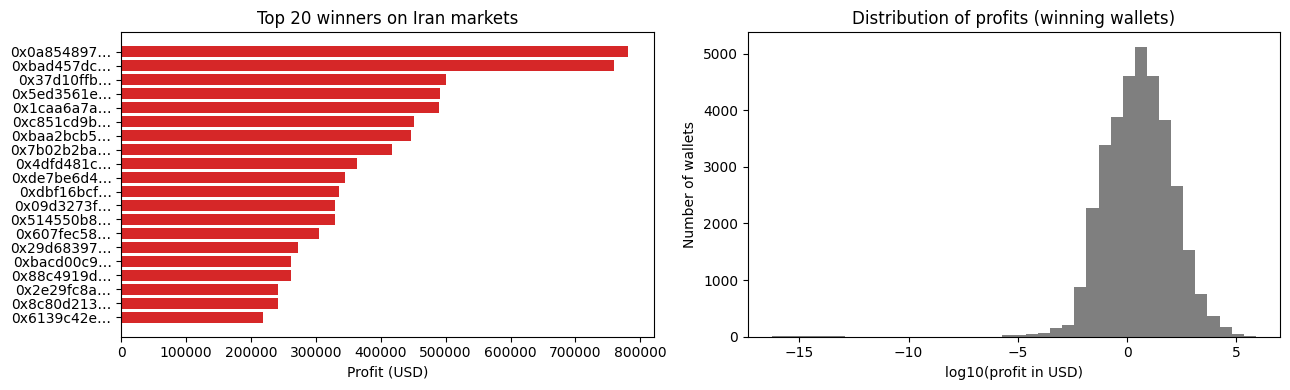

The top 10 wallets capture 19.7% of all profits made on these markets.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
top = winners.head(20)
axes[0].barh(top["wallet"].str[:10] + "…", top["profit"], color="tab:red")
axes[0].invert_yaxis()
axes[0].set_title("Top 20 winners on Iran markets")
axes[0].set_xlabel("Profit (USD)")

pos = wallet_stats[wallet_stats["profit"] > 0]["profit"]
axes[1].hist(np.log10(pos), bins=40, color="tab:gray")
axes[1].set_title("Distribution of profits (winning wallets)")
axes[1].set_xlabel("log10(profit in USD)")
axes[1].set_ylabel("Number of wallets")
plt.tight_layout()
plt.show()

share_top10 = winners.head(10)["profit"].sum() / pos.sum()
print(f"The top 10 wallets capture {share_top10:.1%} of all profits made on these markets.")

### 1.6 Money flows between wallets

With the default `TRANSFER_SOURCE = "polymarket"` no API key is needed. We combine two public sources:

1. **Polymarket's activity feed** (`/v2/activity`) for the winners and the biggest stakers (`ACTIVITY_WALLETS` wallets in total). We keep three activity types:
   - `TIP`: a pUSD transfer from one Polymarket user to another, outside any bet (`side` = `IN` received, `OUT` sent),
   - `DEPOSIT`: money arriving in the wallet,
   - `WITHDRAWAL`: money leaving it.
2. The activity rows do not say **who is on the other side**. When both sides of a tip were downloaded, the shared transaction hash links them directly. For the other rows, we ask a **public Polygon node** for the transaction receipt (`eth_getTransactionReceipt`): its `Transfer` events contain the sender and the receiver. This reveals the wallets that funded the winners and the wallets that received their gains, even if those never placed a bet.

Every row becomes a transfer `from → to` with an amount and a date, exactly like an Etherscan export, so the rest of the notebook does not change. Downloads and node look-ups are cached, so an interrupted run resumes where it stopped.

> Limitation: we only see flows that touch at least one of the downloaded wallets, one hop away. A common funder is still detected when it funded two of them directly.

In [10]:
TRANSFER_TOPIC = "0xddf252ad1be2c89b69c2b068fc378daa952ba7f163c4a11628f55a4df523b3ef"  # ERC-20 Transfer event
TRANSFER_COLUMNS = ["from", "to", "amount", "timestamp", "token", "tx_hash"]

def fetch_wallet_activity(wallet):
    # tips, deposits and withdrawals of one wallet, full history (Data API v2, cursor pagination)
    params = {"user": wallet, "type": "TIP,DEPOSIT,WITHDRAWAL", "exclude_deposits_withdrawals": "false",
              "start": 1, "limit": 1000}
    out, cursor = [], None
    while True:
        res = get_json(f"{DATA_API}/v2/activity", params=dict(params, cursor=cursor) if cursor else params)
        if not res:
            break
        out.extend(res.get("data") or [])
        cursor = (res.get("pagination") or {}).get("next_cursor")
        if not cursor:
            break
    return out

def normalise_activity(rows):
    df = pd.DataFrame(rows)
    if df.empty:
        return pd.DataFrame(columns=["wallet", "type", "side", "amount", "timestamp", "tx_hash"])
    df = df.rename(columns={"proxy_wallet": "wallet", "proxyWallet": "wallet",
                            "transaction_hash": "tx_hash", "transactionHash": "tx_hash",
                            "usdc_size": "usdc", "usdcSize": "usdc"})
    df["wallet"] = df["wallet"].str.lower()
    df["type"] = df["type"].str.upper()
    df["side"] = df.get("side", pd.Series("", index=df.index)).fillna("").str.upper()
    usdc = pd.to_numeric(df.get("usdc", 0), errors="coerce").fillna(0)
    size = pd.to_numeric(df.get("size", 0), errors="coerce").fillna(0)
    df["amount"] = np.where(usdc > 0, usdc, size)
    df["timestamp"] = pd.to_datetime(df["timestamp"].astype(int), unit="s", utc=True)
    df["tx_hash"] = df["tx_hash"].str.lower()
    # direction of the money for this wallet
    df.loc[df["type"] == "DEPOSIT", "side"] = "IN"
    df.loc[df["type"] == "WITHDRAWAL", "side"] = "OUT"
    return df[["wallet", "type", "side", "amount", "timestamp", "tx_hash"]]

def rpc_receipt(tx_hash):
    payload = {"jsonrpc": "2.0", "id": 1, "method": "eth_getTransactionReceipt", "params": [tx_hash]}
    for url in POLYGON_RPCS:
        for attempt in range(3):
            try:
                r = requests.post(url, json=payload, timeout=20)
                if r.status_code == 429:
                    time.sleep(2 ** attempt)
                    continue
                result = r.json().get("result")
                if result:
                    return result
                break
            except (requests.RequestException, ValueError):
                time.sleep(1)
    return None

def counterparty(receipt, wallet, side):
    # the other wallet in the ERC-20 Transfer event that moved money into (IN) or out of (OUT) `wallet`
    for log in (receipt or {}).get("logs", []):
        topics = [t.lower() for t in log.get("topics", [])]
        if len(topics) != 3 or topics[0] != TRANSFER_TOPIC:
            continue
        frm, to = "0x" + topics[1][-40:], "0x" + topics[2][-40:]
        if side == "IN" and to == wallet and frm != wallet:
            return frm
        if side == "OUT" and frm == wallet and to != wallet:
            return to
    return None

def load_transfers_polymarket():
    # 1. which wallets: all winners, then the biggest stakers
    others = wallet_stats[~wallet_stats["wallet"].isin(winner_set)].sort_values("staked", ascending=False)
    query = list(winners["wallet"]) + list(others["wallet"].head(max(0, ACTIVITY_WALLETS - len(winners))))

    # 2. their tips / deposits / withdrawals (cached per wallet)
    os.makedirs(cached("activity"), exist_ok=True)
    parts = []
    for i, w in enumerate(query):
        path = cached(f"activity/{w}.pkl")
        if os.path.exists(path):
            parts.append(pd.read_pickle(path))
            continue
        part = normalise_activity(fetch_wallet_activity(w))
        part.to_pickle(path)
        parts.append(part)
        if (i + 1) % 50 == 0:
            print(f"  activity: {i+1}/{len(query)} wallets")
    act = pd.concat(parts, ignore_index=True).drop_duplicates(["wallet", "tx_hash", "type", "side", "amount"])
    print(f"  {len(act)} activity rows: " + ", ".join(f"{k} {v}" for k, v in act["type"].value_counts().items()))

    # 3. tips whose two sides we both downloaded: matched on the transaction hash
    tips = act[act["type"] == "TIP"]
    sent = tips[tips["side"] == "OUT"][["wallet", "tx_hash", "amount", "timestamp"]].rename(columns={"wallet": "from"})
    recv = tips[tips["side"] == "IN"][["wallet", "tx_hash"]].rename(columns={"wallet": "to"})
    matched = sent.merge(recv, on="tx_hash")
    matched = matched[matched["from"] != matched["to"]]
    matched_keys = set(zip(matched["from"], matched["tx_hash"])) | set(zip(matched["to"], matched["tx_hash"]))

    # 4. everything else: find the other side on a public Polygon node
    rows = [{"from": r["from"], "to": r["to"], "amount": r["amount"], "timestamp": r["timestamp"],
             "token": "PUSD", "tx_hash": r["tx_hash"]} for _, r in matched.iterrows()]
    todo = act[[(w, h) not in matched_keys for w, h in zip(act["wallet"], act["tx_hash"])]]
    if RESOLVE_WITH_RPC and len(todo):
        receipts_path = cached("receipts.pkl")
        receipts = pd.read_pickle(receipts_path) if os.path.exists(receipts_path) else {}
        hashes = [h for h in todo["tx_hash"].unique() if h not in receipts][:MAX_RECEIPTS]
        print(f"  looking up {len(hashes)} transactions on a public Polygon node "
              f"({len(receipts)} already cached)")
        for i, h in enumerate(hashes):
            receipts[h] = rpc_receipt(h)
            if (i + 1) % 200 == 0:
                pd.to_pickle(receipts, receipts_path)
                print(f"    {i+1}/{len(hashes)}")
        pd.to_pickle(receipts, receipts_path)
        unresolved = 0
        for r in todo.itertuples(index=False):
            other = counterparty(receipts.get(r.tx_hash), r.wallet, r.side)
            if other is None:
                unresolved += 1
                continue
            frm, to = (other, r.wallet) if r.side == "IN" else (r.wallet, other)
            rows.append({"from": frm, "to": to, "amount": r.amount, "timestamp": r.timestamp,
                         "token": r.type, "tx_hash": r.tx_hash})
        print(f"  {len(todo) - unresolved} rows resolved to a counterparty, {unresolved} unresolved")

    transfers = pd.DataFrame(rows, columns=TRANSFER_COLUMNS).drop_duplicates(["tx_hash", "from", "to", "amount"])

    # first time money arrived in each wallet (used to detect fresh wallets)
    incoming = act[act["side"] == "IN"]
    first_funding = incoming.groupby("wallet")["timestamp"].min()
    return transfers, first_funding

def load_transfers_etherscan():
    if os.path.exists(cached("transfers.pkl")):
        return pd.read_pickle(cached("transfers.pkl"))
    raw, done = [], set()
    for i, w in enumerate(winners["wallet"]):
        raw.extend(fetch_token_transfers(w))
        done.add(w)
        if (i + 1) % 25 == 0:
            print(f"  winners: {i+1}/{len(winners)}")
    df = normalise_transfers(raw)
    if EXPAND_FUNDERS:
        # rank funders by the number of distinct winners they funded: exchanges and bridges come first,
        # so their full history is downloaded and their very high degree gets them removed as hubs
        funded = df[df["to"].isin(winner_set)].groupby("from")["to"].nunique().sort_values(ascending=False)
        funders = [f for f in funded.index
                   if f not in done and f not in KNOWN_CONTRACTS][:MAX_FUNDERS_TO_EXPAND]
        print(f"  expanding {len(funders)} funders")
        for f in funders:
            raw.extend(fetch_token_transfers(f))
        df = normalise_transfers(raw)
    df = df.drop_duplicates(["tx_hash", "from", "to", "amount"])
    df.to_pickle(cached("transfers.pkl"))
    return df

if DATA_MODE == "synthetic":
    FIRST_FUNDING = transfers_all.groupby("to")["timestamp"].min()
elif TRANSFER_SOURCE == "polymarket":
    transfers_all, FIRST_FUNDING = load_transfers_polymarket()
else:
    if TRANSFER_SOURCE == "csv":
        transfers_all = pd.read_csv(TRANSFERS_CSV)
        transfers_all["timestamp"] = pd.to_datetime(transfers_all["timestamp"], utc=True)
        transfers_all["from"] = transfers_all["from"].str.lower()
        transfers_all["to"] = transfers_all["to"].str.lower()
    else:
        transfers_all = load_transfers_etherscan()
    FIRST_FUNDING = transfers_all.groupby("to")["timestamp"].min()

print(f"{len(transfers_all)} transfers between "
      f"{pd.unique(transfers_all[['from', 'to']].values.ravel()).size} addresses")
transfers_all.head()

  activity: 50/500 wallets
  activity: 100/500 wallets
  activity: 150/500 wallets
  activity: 200/500 wallets
  activity: 250/500 wallets
  activity: 300/500 wallets
  activity: 350/500 wallets
  activity: 400/500 wallets
  activity: 450/500 wallets
  activity: 500/500 wallets


/tmp/ipykernel_2765/1983061394.py:87: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  act = pd.concat(parts, ignore_index=True).drop_duplicates(["wallet", "tx_hash", "type", "side", "amount"])


  55503 activity rows: DEPOSIT 27092, WITHDRAWAL 26695, TIP 1716
  looking up 20000 transactions on a public Polygon node (0 already cached)
    200/20000
    400/20000
    600/20000
    800/20000
    1000/20000
    1200/20000
    1400/20000
    1600/20000
    1800/20000
    2000/20000
    2200/20000
    2400/20000
    2600/20000
    2800/20000
    3000/20000
    3200/20000
    3400/20000
    3600/20000
    3800/20000
    4000/20000
    4200/20000
    4400/20000
    4600/20000
    4800/20000
    5000/20000
    5200/20000
    5400/20000
    5600/20000
    5800/20000
    6000/20000
    6200/20000
    6400/20000
    6600/20000
    6800/20000
    7000/20000
    7200/20000
    7400/20000
    7600/20000
    7800/20000
    8000/20000
    8200/20000
    8400/20000
    8600/20000
    8800/20000
    9000/20000
    9200/20000
    9400/20000
    9600/20000
    9800/20000
    10000/20000
    10200/20000
    10400/20000
    10600/20000
    10800/20000
    11000/20000
    11200/20000
    11400/20000


,from,to,amount,timestamp,token,tx_hash
0,0xc851cd9bee7d262afd78674f861f9f576a12cd2a,0x08458f7e9d2858027de579e4c3ca305475496b6f,2000.0,2026-11-05 11:57:06+00:00,PUSD,0x4e456697c497e992ba435a08228f47ff4cefd5ec942a...
1,0xc851cd9bee7d262afd78674f861f9f576a12cd2a,0x08458f7e9d2858027de579e4c3ca305475496b6f,4560.0,2026-10-20 13:51:47+00:00,PUSD,0xfe0a2d724e9cd2aaaf669c42c0b546952433305002c7...
2,0xc851cd9bee7d262afd78674f861f9f576a12cd2a,0x1cc16713196d456f86fa9c7387dd326a7f73b8df,50000.0,2026-10-19 10:24:30+00:00,PUSD,0xa01247286878789fbacbd0defe97c4d790c57fcc757e...
3,0xc851cd9bee7d262afd78674f861f9f576a12cd2a,0x401ee31e9ebf9ab9f6315cd95faca5f950436fc9,350.0,2026-10-14 16:06:30+00:00,PUSD,0x76e7b112252a8ea2a01fb2bbbf17db2f2c20ea96ebed...
4,0xc851cd9bee7d262afd78674f861f9f576a12cd2a,0x614dc8d3542c12103d2c6a3553fd761e391d1546,100.0,2026-08-20 08:46:30+00:00,PUSD,0x934384d8321ede51e2e70df5fc7b8fc59f98e65b3221...


## 2. Building the money-flow graph

- **Nodes**: wallet addresses.
- **Edges**: directed `A → B` if A sent stablecoins to B. Parallel transfers are merged; the edge stores the total `amount`, the number of transfers `count`, and the first/last date.

**Cleaning.** Exchanges, bridges and Polymarket's own contracts are connected to almost everyone. If we keep them, two unrelated users of the same exchange would look "linked". We remove the known contracts and every address whose number of distinct counterparties exceeds `HUB_DEGREE_THRESHOLD`, and we keep a list of them for reference.

In [11]:
def build_flow_graph(transfers):
    agg = transfers.groupby(["from", "to"]).agg(
        amount=("amount", "sum"), count=("amount", "size"),
        first_ts=("timestamp", "min"), last_ts=("timestamp", "max")).reset_index()
    G = nx.DiGraph()
    for r in agg.itertuples(index=False):
        if r[0] == r[1]:
            continue
        G.add_edge(r[0], r[1], amount=float(r.amount), count=int(r.count),
                   first_ts=r.first_ts, last_ts=r.last_ts)
    return G

G_raw = build_flow_graph(transfers_all)

undirected_degree = {n: len(set(G_raw.predecessors(n)) | set(G_raw.successors(n))) for n in G_raw}
hubs = {n for n, d in undirected_degree.items() if d > HUB_DEGREE_THRESHOLD and n not in winner_set}
hubs |= (KNOWN_CONTRACTS & set(G_raw.nodes))

G = G_raw.copy()
G.remove_nodes_from(hubs)
G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])

# node attributes
stats_idx = wallet_stats.set_index("wallet")
for n in G:
    G.nodes[n]["winner"] = n in winner_set
    G.nodes[n]["profit"] = float(stats_idx.at[n, "profit"]) if n in stats_idx.index else 0.0

if G.size() == 0:
    raise RuntimeError("The money-flow graph is empty: no transfer links the downloaded wallets. "
                       "Increase ACTIVITY_WALLETS, check that RESOLVE_WITH_RPC works, or use another TRANSFER_SOURCE.")

print(f"Raw graph: {G_raw.order()} nodes, {G_raw.size()} edges")
print(f"Removed {len(hubs)} hubs/contracts: " + ", ".join(sorted(h[:10] + '…' for h in hubs))[:300])
print(f"Clean graph: {G.order()} nodes, {G.size()} edges, "
      f"{sum(1 for n in G if G.nodes[n]['winner'])} winners present")

Raw graph: 221 nodes, 375 edges
Removed 1 hubs/contracts: 0x00000000…
Clean graph: 214 nodes, 326 edges, 47 winners present


In [12]:
def short(addr):
    return addr[:6] + "…" + addr[-4:]

def label(n):
    # readable label: shortened address, plus "(W)" for winners
    return short(n) + (" (W)" if G.nodes[n].get("winner") else "")

# Undirected simple copy used by measures that require it (distances, clustering, communities)
G_u = nx.Graph()
for u, v, d in G.edges(data=True):
    if G_u.has_edge(u, v):
        G_u[u][v]["amount"] += d["amount"]
        G_u[u][v]["count"] += d["count"]
    else:
        G_u.add_edge(u, v, amount=d["amount"], count=d["count"])
for u, v, d in G_u.edges(data=True):
    d["log_amount"] = float(np.log1p(d["amount"]))   # tames the heavy-tailed amounts for weighting
nx.set_node_attributes(G_u, {n: G.nodes[n] for n in G_u})

largest_cc_nodes = max(nx.connected_components(G_u), key=len)
G_lcc = G_u.subgraph(largest_cc_nodes).copy()

In [40]:
# --- DOWNLOAD THE CACHE FOLDER ---
import shutil
from google.colab import files
import pandas as pd

G_export = G.copy()

for n, attrs in G_export.nodes(data=True):
    for k, v in list(attrs.items()):
        if isinstance(v, pd.Timestamp):
            attrs[k] = v.isoformat()

for u, v, attrs in G_export.edges(data=True):
    for k, v in list(attrs.items()):
        if isinstance(v, pd.Timestamp):
            attrs[k] = v.isoformat()

nx.write_graphml(G_export, "polymarket_iran_graph.graphml")
print("Graph saved to 'polymarket_iran_graph.graphml'")

# Zip the folder
shutil.make_archive("polymarket_cache_backup", 'zip', CACHE_DIR)
print("Cache folder compressed to 'polymarket_cache_backup.zip'")

# Download
files.download("polymarket_iran_graph.graphml")
files.download("polymarket_cache_backup.zip")

# Note: In your next session, you simply need to import the zip file
# and extract it into the "polymarket_cache" folder; the notebook will then pick up the data from there!

Graph saved to 'polymarket_iran_graph.graphml'
Cache folder compressed to 'polymarket_cache_backup.zip'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3. Graph statistics

### 3.1 Basic structure
- **Order**: number of nodes.
- **Size**: number of edges.
- **Graph type**: directed (money flows from sender to receiver) and weighted (amount, number of transfers).
- **Density**: share of all possible edges that actually exist.

In [14]:
basic = {
    "Order (nodes)": G.order(),
    "Size (edges)": G.size(),
    "Directed": G.is_directed(),
    "Weighted": nx.is_weighted(G, weight="amount"),
    "Density": nx.density(G),
    "Total volume (USD)": sum(d["amount"] for _, _, d in G.edges(data=True)),
    "Winners in graph": sum(1 for n in G if G.nodes[n]["winner"]),
}
pd.Series(basic, name="value").to_frame().style.format(
    lambda v: f"{v:,.6f}" if isinstance(v, float) and v < 1 else (f"{v:,.0f}" if isinstance(v, (int, float)) and not isinstance(v, bool) else v))

,value
Order (nodes),214
Size (edges),326
Directed,True
Weighted,True
Density,0.007152
Total volume (USD),"38,404,414"
Winners in graph,47


**Interpretation.** Transaction graphs are extremely sparse: each wallet only interacts with a handful of others, so the density is close to 0. This is expected and makes local patterns (a few wallets exchanging money among themselves) easy to spot.

### 3.2 Degree

In a directed graph we distinguish:
- **in-degree**: number of distinct wallets that sent money to this wallet (funders),
- **out-degree**: number of distinct wallets that received money from it,
- **degree**: in + out.

In [15]:
deg = dict(nx.degree(G))
in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())

degree_table = pd.DataFrame({
    "degree": pd.Series(deg), "in_degree": pd.Series(in_deg), "out_degree": pd.Series(out_deg)})
print(degree_table.agg(["min", "max", "mean"]).round(2))

winners_deg = degree_table.loc[[n for n in G if G.nodes[n]["winner"]]]
print("\nWinners only:")
print(winners_deg.agg(["min", "max", "mean"]).round(2))

      degree  in_degree  out_degree
min     1.00       0.00        0.00
max    68.00      68.00       30.00
mean    3.05       1.52        1.52

Winners only:
      degree  in_degree  out_degree
min      1.0       0.00        0.00
max     35.0      19.00       16.00
mean     4.3       1.85        2.45


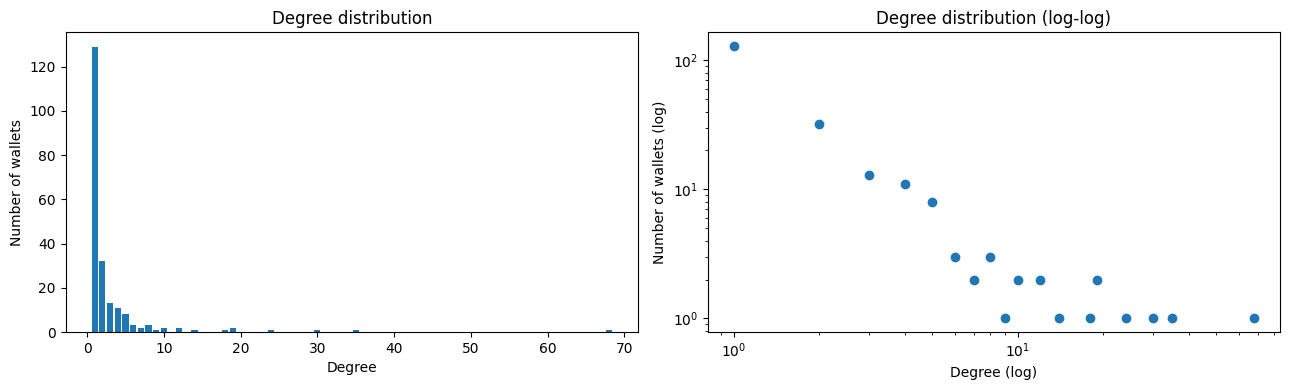

Top 10 wallets by degree:
  0xc011…2dfb            degree= 68  in= 68  out=  0
  0x44c1…ebc1 (W)        degree= 35  in= 19  out= 16
  0xd152…2150            degree= 30  in=  0  out= 30
  0x7c3d…5c6b            degree= 24  in= 13  out= 11
  0x35bb…009b            degree= 19  in=  6  out= 13
  0xdca4…17d2            degree= 19  in= 11  out=  8
  0x614d…1546 (W)        degree= 18  in=  9  out=  9
  0x6139…6b7a (W)        degree= 14  in=  5  out=  9
  0x6d9f…9790            degree= 12  in=  5  out=  7
  0xe25b…0f1b (W)        degree= 12  in=  5  out=  7


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = Counter(deg.values())
axes[0].bar(list(counts.keys()), list(counts.values()), color="tab:blue")
axes[0].set_title("Degree distribution")
axes[0].set_xlabel("Degree")
axes[0].set_ylabel("Number of wallets")

k, c = zip(*sorted(counts.items()))
axes[1].loglog(k, c, "o", color="tab:blue")
axes[1].set_title("Degree distribution (log-log)")
axes[1].set_xlabel("Degree (log)")
axes[1].set_ylabel("Number of wallets (log)")
plt.tight_layout()
plt.show()

print("Top 10 wallets by degree:")
for n in sorted(deg, key=deg.get, reverse=True)[:10]:
    print(f"  {label(n):22s} degree={deg[n]:3d}  in={in_deg[n]:3d}  out={out_deg[n]:3d}")

**Interpretation.** A roughly straight line on the log-log plot indicates a heavy-tailed distribution: most wallets have one or two counterparties, while a few act as **hubs**. After removing exchanges, the remaining hubs are interesting: a wallet with a high **out-degree** that funds several winners is a candidate "master" wallet, and a wallet with a high **in-degree** receiving money from several winners is a candidate "collector".

### 3.3 Connectivity

- **Weakly connected components**: groups of wallets linked by transfers if we ignore the direction.
- **Strongly connected components**: groups where money can flow from any wallet to any other following the direction (i.e. money circulates in loops).

In [17]:
wccs = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
sccs = [c for c in nx.strongly_connected_components(G) if len(c) > 1]

print("Weakly connected components:", nx.number_weakly_connected_components(G))
print("Strongly connected components:", nx.number_strongly_connected_components(G),
      f"(of which {len(sccs)} contain more than one wallet, i.e. money loops)")
print(f"Largest weakly connected component: {len(wccs[0])} wallets "
      f"({len(wccs[0]) / G.order():.1%} of the graph)")

comp_rows = []
for i, comp in enumerate(wccs):
    w = [n for n in comp if G.nodes[n]["winner"]]
    if w:
        comp_rows.append({"component": i, "size": len(comp), "winners": len(w),
                          "winners_profit": sum(G.nodes[n]["profit"] for n in w)})
comp_df = pd.DataFrame(comp_rows).sort_values("winners", ascending=False)
print(f"\nComponents containing at least 2 winners: {(comp_df['winners'] >= 2).sum()}")
comp_df.head(10)

Weakly connected components: 2
Strongly connected components: 169 (of which 6 contain more than one wallet, i.e. money loops)
Largest weakly connected component: 212 wallets (99.1% of the graph)

Components containing at least 2 winners: 1


,component,size,winners,winners_profit
0,0,212,47,6.594036e+06


**Interpretation.** Once exchanges are removed, unrelated users fall apart into many small components. A component that still contains **several winners** means these winners are connected by a chain of direct transfers, independently of any exchange: this is the first structural signal of linked accounts.

### 3.4 Distances

Distances are computed on the **undirected** version of the **largest connected component**, because the diameter is infinite as soon as two wallets cannot reach each other. For large graphs, exact computation is slow, so we use an approximation (a 2-sweep lower bound for the diameter and a sample of source nodes for the average path length).

In [18]:
def distance_stats(H, exact_limit=2000, sample=300, seed=SEED):
    n = H.order()
    if n <= exact_limit:
        return {"nodes": n, "diameter": nx.diameter(H), "radius": nx.radius(H),
                "avg_shortest_path": nx.average_shortest_path_length(H), "method": "exact"}
    rng = random.Random(seed)
    sources = rng.sample(list(H.nodes), min(sample, n))
    ecc, total, pairs = [], 0, 0
    for s in sources:
        lengths = nx.single_source_shortest_path_length(H, s)
        ecc.append(max(lengths.values()))
        total += sum(lengths.values())
        pairs += len(lengths) - 1
    return {"nodes": n, "diameter": nx.approximation.diameter(H, seed=seed),
            "radius": min(ecc), "avg_shortest_path": total / pairs,
            "method": f"approximate ({len(sources)} sampled sources; radius is an upper bound)"}

dist = distance_stats(G_lcc)
pd.Series(dist, name="largest component").to_frame()

,largest component
nodes,212
diameter,7
radius,4
avg_shortest_path,3.257891
method,exact


**Interpretation.** The **diameter** is the longest shortest path; the **radius** is the eccentricity of the most central wallet; the **average shortest path length** is the typical number of transfers separating two wallets. Small values inside a suspicious cluster mean that every wallet is only one or two transfers away from the others, as expected if a single entity controls them.

### 3.5 Local structure
- **Average clustering coefficient**: on average, how often the neighbours of a wallet also transacted with each other.
- **Transitivity**: global share of closed triangles.

In [19]:
local = {
    "Average clustering (whole graph)": nx.average_clustering(G_u),
    "Transitivity (whole graph)": nx.transitivity(G_u),
    "Average clustering (largest component)": nx.average_clustering(G_lcc),
    "Transitivity (largest component)": nx.transitivity(G_lcc),
}
winner_nodes_u = [n for n in G_u if G_u.nodes[n].get("winner")]
local["Average clustering (winners)"] = np.mean(list(nx.clustering(G_u, winner_nodes_u).values())) if winner_nodes_u else np.nan
pd.Series(local, name="value").round(4).to_frame()

,value
Average clustering (whole graph),0.0470
Transitivity (whole graph),0.0291
Average clustering (largest component),0.0475
Transitivity (largest component),0.0291
Average clustering (winners),0.0258


**Interpretation.** Money-flow graphs usually have very low clustering (money goes from A to B to C, rarely in triangles), and star shapes (one funder, many receivers) have a clustering of zero. A triangle such as *master → bettor → collector ← master* closes a loop and raises the clustering locally, which is why a higher value around winners than in the rest of the graph is a meaningful signal.

### 3.6 Centrality measures

- **Degree centrality**: wallets with the most direct counterparties.
- **Betweenness centrality**: wallets that lie on many shortest paths between others — the bridges and relays of the network (approximated with a sample of `k` nodes on large graphs).
- **Closeness centrality**: wallets that are, on average, closest to all others.
- **PageRank** (weighted by amount, directed): a wallet is important if it receives large amounts from important wallets — good for spotting **collectors**.
- **Eigenvector centrality**: same idea as PageRank without damping, computed on the undirected largest component.

In [20]:
def top_k_central_nodes(G, k: int, centrality_measure, show=True):
    topk = sorted(centrality_measure, key=centrality_measure.get, reverse=True)[:k]
    if show:
        for node in topk:
            print(f"  {label(node):22s} {centrality_measure[node]:.4f}")
    return topk

k_sample = min(500, G_u.order())
measures = {
    "degree": nx.degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G_u, k=k_sample, seed=SEED),
    "closeness": nx.closeness_centrality(G_lcc),
    "PageRank": nx.pagerank(G, weight="amount"),
}
try:
    measures["eigenvector"] = nx.eigenvector_centrality(G_lcc, max_iter=2000, weight="log_amount")
except nx.PowerIterationFailedConvergence:
    print("Eigenvector centrality did not converge; skipped.")

all_top = []
for name, values in measures.items():
    print(f"\n=== Top 10: {name} ===")
    all_top += top_k_central_nodes(G, 10, values)


=== Top 10: degree ===
  0xc011…2dfb            0.3192
  0x44c1…ebc1 (W)        0.1643
  0xd152…2150            0.1408
  0x7c3d…5c6b            0.1127
  0x35bb…009b            0.0892
  0xdca4…17d2            0.0892
  0x614d…1546 (W)        0.0845
  0x6139…6b7a (W)        0.0657
  0x6d9f…9790            0.0563
  0xe25b…0f1b (W)        0.0563

=== Top 10: betweenness ===
  0xc011…2dfb            0.6715
  0x44c1…ebc1 (W)        0.1944
  0xd152…2150            0.1584
  0x7c3d…5c6b            0.1387
  0x614d…1546 (W)        0.0989
  0x35bb…009b            0.0920
  0x6139…6b7a (W)        0.0756
  0xdbf1…86b5 (W)        0.0584
  0x8f7a…db40            0.0533
  0x6bab…1292 (W)        0.0470

=== Top 10: closeness ===
  0xc011…2dfb            0.5553
  0x44c1…ebc1 (W)        0.4480
  0x7c3d…5c6b            0.4387
  0x35bb…009b            0.4212
  0xbacd…ab35 (W)        0.4058
  0xe25b…0f1b (W)        0.4050
  0x614d…1546 (W)        0.3907
  0xbaa2…2c73 (W)        0.3900
  0xd152…2150           

#### Top-k overlap

We concatenate the top-10 lists of all measures and count how often each wallet appears. A wallet present in the top 10 of most measures is central whatever the definition of importance.

In [21]:
counter = Counter(all_top)
overlap = pd.DataFrame(counter.most_common(), columns=["wallet", "appearances"])
overlap["label"] = overlap["wallet"].map(label)
overlap["winner"] = overlap["wallet"].map(lambda n: G.nodes[n]["winner"])
overlap["in_degree"] = overlap["wallet"].map(in_deg)
overlap["out_degree"] = overlap["wallet"].map(out_deg)
overlap.head(15)[["label", "appearances", "winner", "in_degree", "out_degree"]]

,label,appearances,winner,in_degree,out_degree
0,0xc011…2dfb,5,False,68,0
1,0x44c1…ebc1 (W),5,True,19,16
2,0x7c3d…5c6b,5,False,13,11
3,0x35bb…009b,4,False,6,13
4,0x614d…1546 (W),4,True,9,9
5,0xd152…2150,3,False,0,30
6,0xdca4…17d2,3,False,11,8
7,0x6139…6b7a (W),3,True,5,9
8,0xe25b…0f1b (W),3,True,5,7
9,0xdbf1…86b5 (W),2,True,6,4


**Why the rankings differ.** Degree is purely local; betweenness rewards relays sitting between groups even with few neighbours; closeness rewards wallets in the middle of the largest component; PageRank follows the direction and the amounts, so it ranks wallets where large sums end up. In this context, **non-winning wallets** that appear in several top-10 lists are the most interesting: they are the potential funders and collectors around the winners.

#### Edge betweenness: which transfers act as bridges

As in the course TP on the metro network, betweenness can also be computed for **edges**: an edge with a high value lies on many shortest paths, so it acts as a **bridge** between parts of the network. Here, an edge is a money transfer relationship between two wallets. We then check, edge by edge, whether removing it disconnects the graph.

Top 10 edges by betweenness centrality:
  0xc011…2dfb            — 0x44c1…ebc1 (W)        0.0808   amount=     970,347 USD
  0xc011…2dfb            — 0x614d…1546 (W)        0.0793   amount=     725,677 USD
  0xc011…2dfb            — 0x6139…6b7a (W)        0.0664   amount=     111,290 USD
  0xc011…2dfb            — 0x7c3d…5c6b            0.0650   amount=      36,321 USD
  0xc011…2dfb            — 0x35bb…009b            0.0559   amount=     122,501 USD
  0xc011…2dfb            — 0x8f7a…db40            0.0559   amount=      17,530 USD
  0xc011…2dfb            — 0xdbf1…86b5 (W)        0.0505   amount=       3,000 USD
  0xc011…2dfb            — 0x6bab…1292 (W)        0.0472   amount=     188,239 USD
  0xc011…2dfb            — 0xbaa2…2c73 (W)        0.0382   amount=     840,019 USD
  0x44c1…ebc1 (W)        — 0xd152…2150            0.0336   amount=           0 USD

153 of 293 edges disconnect the graph when removed (NetworkX finds 153 bridges).


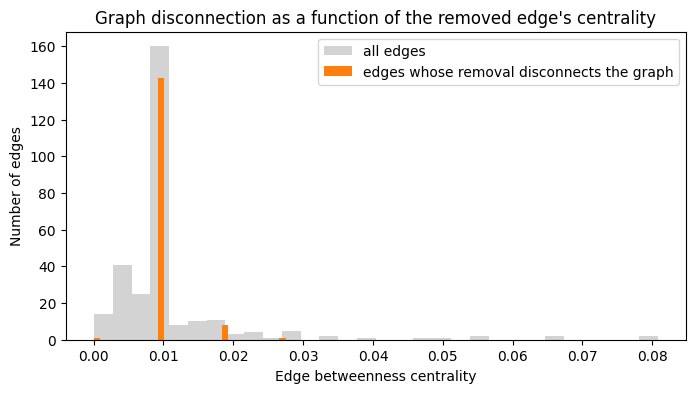

In [22]:
ebc = nx.edge_betweenness_centrality(G_u)
top_edges = sorted(ebc, key=ebc.get, reverse=True)[:10]

print("Top 10 edges by betweenness centrality:")
for u, v in top_edges:
    print(f"  {label(u):22s} — {label(v):22s} {ebc[(u, v)]:.4f}   amount={G_u[u][v]['amount']:>12,.0f} USD")

# Impact of removing each edge on connectivity (same idea as the TP)
n_components = nx.number_connected_components(G_u)
disconnecting = []
for (u, v), value in sorted(ebc.items(), key=lambda x: x[1], reverse=True):
    H = G_u.copy()
    H.remove_edge(u, v)
    if nx.number_connected_components(H) > n_components:
        disconnecting.append(value)

print(f"\n{len(disconnecting)} of {G_u.size()} edges disconnect the graph when removed "
      f"(NetworkX finds {len(list(nx.bridges(G_u)))} bridges).")

plt.figure(figsize=(8, 4))
plt.hist([ebc[e] for e in ebc], bins=30, color="lightgray", label="all edges")
plt.hist(disconnecting, bins=30, color="tab:orange", label="edges whose removal disconnects the graph")
plt.xlabel("Edge betweenness centrality")
plt.ylabel("Number of edges")
plt.title("Graph disconnection as a function of the removed edge's centrality")
plt.legend()
plt.show()

**Interpretation.** In a transaction graph, most wallets hang on a single transfer (a leaf), so a large share of the edges are bridges: removing them isolates one wallet. The edges with the highest betweenness are different: they connect whole groups of wallets, often through a hub such as an exchange or a funder. A bridge between two winners, or between a winner and a funder, is a concrete link worth checking by hand.

#### Correlation between centrality and profit

The course TP correlates the **traffic** of each metro station with its centrality. Here, the natural equivalent is the **profit** of each wallet on the Iran markets: are the most central wallets in the money-flow graph also the ones that won the most?

- **Pearson** measures a *linear* relationship and is sensitive to a few huge profits.
- **Spearman** measures a *monotonic* relationship on ranks, which is more robust here because profits are very heavy-tailed.

We only use wallets that traded on the selected markets (so that their profit is known).

In [23]:
from scipy.stats import pearsonr, spearmanr

traders = [n for n in G if n in stats_idx.index]
profit = np.array([G.nodes[n]["profit"] for n in traders])

rows = []
for name, values in measures.items():
    x = np.array([values.get(n, 0.0) for n in traders])
    if np.std(x) == 0:
        continue
    r_p, p_p = pearsonr(x, profit)
    r_s, p_s = spearmanr(x, profit)
    rows.append({"measure": name, "pearson_r": r_p, "pearson_p": p_p,
                 "spearman_rho": r_s, "spearman_p": p_s})

corr_df = pd.DataFrame(rows).set_index("measure")
print(f"{len(traders)} wallets with a known profit")
corr_df.round(3)

140 wallets with a known profit


,pearson_r,pearson_p,spearman_rho,spearman_p
measure,,,,
degree,0.119,0.161,0.296,0.000
betweenness,0.103,0.225,0.369,0.000
closeness,0.020,0.812,0.422,0.000
PageRank,0.120,0.156,0.212,0.012
eigenvector,-0.005,0.954,0.420,0.000


**Interpretation.** A weak correlation means that **winning is not explained by being central**: most big winners are peripheral wallets with one or two counterparties, which is consistent with fresh wallets created for a single bet. A significant positive correlation would instead suggest that profits concentrate around hubs. Check the p-values: with a few hundred wallets, correlations below about 0.1 in absolute value are usually not significant.

### 3.7 Community detection

We run the **Louvain** algorithm on the undirected graph, weighted by `log(1 + amount)`, and measure the **modularity** of the partition (above about 0.3 indicates clear communities).

In [24]:
communities = nx.community.louvain_communities(G_u, weight="log_amount", seed=SEED)
communities = sorted(communities, key=len, reverse=True)
modularity = nx.community.modularity(G_u, communities, weight="log_amount")

print(f"Number of communities: {len(communities)}")
print(f"Modularity: {modularity:.3f}")
sizes = [len(c) for c in communities]
print(f"Largest community: {sizes[0]} wallets, median size: {int(np.median(sizes))}")

pr = measures["PageRank"]
node_community = {}
rows = []
for i, c in enumerate(communities):
    for n in c:
        node_community[n] = i
    w = [n for n in c if G.nodes[n]["winner"]]
    sub = G.subgraph(c)
    rows.append({
        "community": i, "size": len(c), "winners": len(w),
        "winners_profit": sum(G.nodes[n]["profit"] for n in w),
        "internal_volume": sum(d["amount"] for _, _, d in sub.edges(data=True)),
        "most_central_wallet": label(max(c, key=lambda n: pr.get(n, 0))),
    })
community_df = pd.DataFrame(rows)
community_df.sort_values(["winners", "winners_profit"], ascending=False).head(10).style.format(
    {"winners_profit": "{:,.0f}", "internal_volume": "{:,.0f}"})

Number of communities: 10
Modularity: 0.590
Largest community: 50 wallets, median size: 19


,community,size,winners,winners_profit,internal_volume,most_central_wallet
0,0,50,21,"1,752,624","15,830,271",0xc011…2dfb
4,4,22,6,"372,130","640,399",0xdca4…17d2
6,6,15,5,"590,508","394,652",0xe25b…0f1b (W)
7,7,13,4,"2,026,374","2,298,679",0xbaa2…2c73 (W)
3,3,28,4,"963,358","1,794,582",0x614d…1546 (W)
1,1,31,4,"288,881","2,353,641",0x7c3d…5c6b
8,8,7,1,"335,798","2,556,132",0xdbf1…86b5 (W)
5,5,16,1,"218,384","146,304",0x6139…6b7a (W)
2,2,30,1,"45,979","1,052,512",0x44c1…ebc1 (W)
9,9,2,0,0,"1,387",0xcf19…6402


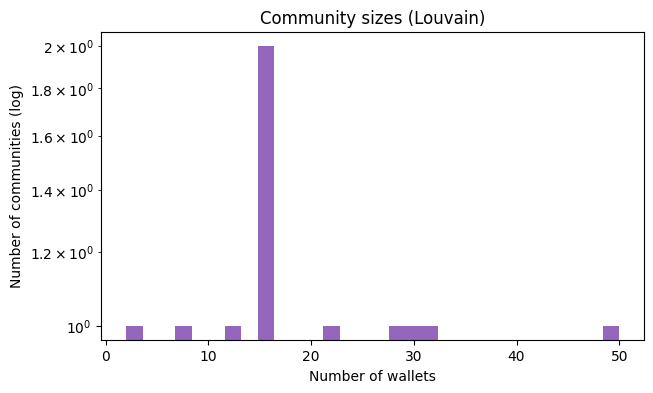

Interpretation of the communities containing several winners:
  Community 7: 13 wallets, 4 winners earning 2,026,374 USD, internal transfers of 2,298,679 USD, most central wallet 0xbaa2…2c73 (W)
  Community 0: 50 wallets, 21 winners earning 1,752,624 USD, internal transfers of 15,830,271 USD, most central wallet 0xc011…2dfb
  Community 3: 28 wallets, 4 winners earning 963,358 USD, internal transfers of 1,794,582 USD, most central wallet 0x614d…1546 (W)
  Community 6: 15 wallets, 5 winners earning 590,508 USD, internal transfers of 394,652 USD, most central wallet 0xe25b…0f1b (W)
  Community 4: 22 wallets, 6 winners earning 372,130 USD, internal transfers of 640,399 USD, most central wallet 0xdca4…17d2
  Community 1: 31 wallets, 4 winners earning 288,881 USD, internal transfers of 2,353,641 USD, most central wallet 0x7c3d…5c6b


In [25]:
plt.figure(figsize=(7, 4))
plt.hist(sizes, bins=30, color="tab:purple")
plt.yscale("log")
plt.title("Community sizes (Louvain)")
plt.xlabel("Number of wallets")
plt.ylabel("Number of communities (log)")
plt.show()

print("Interpretation of the communities containing several winners:")
for r in community_df[community_df["winners"] >= 2].sort_values("winners_profit", ascending=False).itertuples():
    print(f"  Community {r.community}: {r.size} wallets, {r.winners} winners earning {r.winners_profit:,.0f} USD, "
          f"internal transfers of {r.internal_volume:,.0f} USD, most central wallet {r.most_central_wallet}")

**Interpretation.** In a money-flow graph, a community is a group of wallets that exchange more money among themselves than with the rest of the network. Ordinary users end up in many small communities around their own counterparties. A community grouping **several winners** together with a large internal volume is the graph signature of a group of wallets that could be controlled by the same entity: this is what Section 4 investigates in detail.

#### Comparing two community detection algorithms

As in the community detection TP, we compare **Louvain** (which maximises modularity) with **label propagation** (each node repeatedly adopts the most common label among its neighbours). We compare their number of communities, sizes and modularity, and measure how much they agree with the **normalised mutual information (NMI)**: 1 means identical partitions, 0 means unrelated ones.

In [26]:
from sklearn.metrics import normalized_mutual_info_score

communities_lpa = sorted(nx.community.asyn_lpa_communities(G_u, weight="log_amount", seed=SEED),
                         key=len, reverse=True)

def summarise(name, comms):
    sizes = sorted((len(c) for c in comms), reverse=True)
    mod = nx.community.modularity(G_u, comms, weight="log_amount")
    n_winner_comms = sum(1 for c in comms if sum(G.nodes[n]["winner"] for n in c) >= 2)
    print(f"{name}: {len(comms)} communities, modularity = {mod:.3f}")
    print(f"   5 largest sizes: {sizes[:5]}")
    print(f"   single-wallet communities: {sizes.count(1)}")
    print(f"   communities with at least 2 winners: {n_winner_comms}")

def nmi(comms_a, comms_b):
    nodes = list(G_u.nodes)
    a = {n: i for i, c in enumerate(comms_a) for n in c}
    b = {n: i for i, c in enumerate(comms_b) for n in c}
    return normalized_mutual_info_score([a[n] for n in nodes], [b[n] for n in nodes])

summarise("Louvain", communities)
summarise("Label propagation", communities_lpa)
print(f"\nNMI between Louvain and label propagation: {nmi(communities, communities_lpa):.3f}")

# Louvain is randomised: check that the partition is stable across seeds
runs = [nx.community.louvain_communities(G_u, weight="log_amount", seed=s) for s in range(10)]
print(f"Louvain over 10 seeds: {min(map(len, runs))}–{max(map(len, runs))} communities, "
      f"mean NMI with the reference partition = {np.mean([nmi(communities, r) for r in runs]):.3f}")

Louvain: 10 communities, modularity = 0.590
   5 largest sizes: [50, 31, 30, 28, 22]
   single-wallet communities: 0
   communities with at least 2 winners: 6
Label propagation: 15 communities, modularity = 0.362
   5 largest sizes: [137, 14, 12, 8, 8]
   single-wallet communities: 0
   communities with at least 2 winners: 1

NMI between Louvain and label propagation: 0.560
Louvain over 10 seeds: 9–12 communities, mean NMI with the reference partition = 0.956


**Interpretation.** A high NMI between the two algorithms, and between Louvain runs with different seeds, means the communities are a real property of the graph and not an artefact of one algorithm. Communities that both methods find, especially those containing several winners, are the most reliable. Label propagation usually finds more, smaller communities and a lower modularity, since it does not optimise modularity directly.

#### Community graph

As in the TP, we summarise the partition as a **graph of communities**: one node per Louvain community (named after its most central wallet by PageRank, sized by its number of wallets, orange if it contains at least two winners) and one edge between two communities weighted by the money exchanged between them.

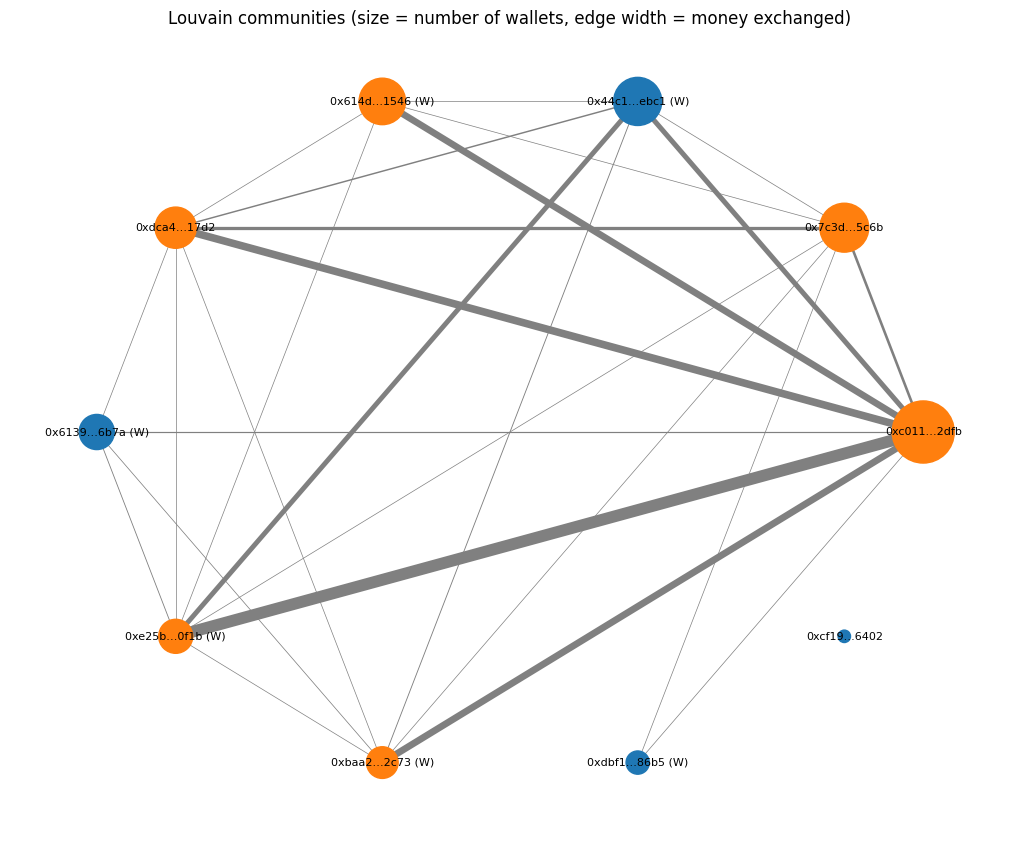

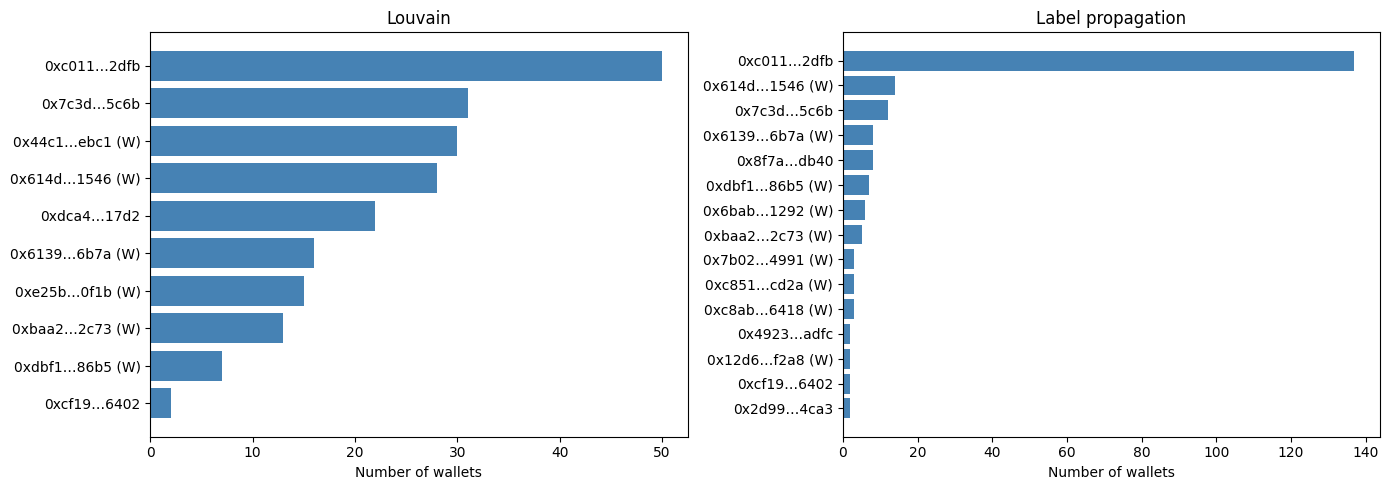

In [27]:
names = [label(max(c, key=lambda n: pr.get(n, 0))) for c in communities]
num = {n: i for i, c in enumerate(communities) for n in c}

C = nx.Graph()
for i, c in enumerate(communities):
    C.add_node(names[i], size=len(c), winners=sum(G.nodes[n]["winner"] for n in c))
for u, v, d in G_u.edges(data=True):
    a, b = names[num[u]], names[num[v]]
    if a != b:
        w = C[a][b]["weight"] + d["amount"] if C.has_edge(a, b) else d["amount"]
        C.add_edge(a, b, weight=w)

weights = [C[u][v]["weight"] for u, v in C.edges()]
plt.figure(figsize=(10, 8))
pos = nx.circular_layout(C)
nx.draw(C, pos, with_labels=True, font_size=8,
        node_color=["tab:orange" if C.nodes[n]["winners"] >= 2 else "tab:blue" for n in C],
        node_size=[C.nodes[n]["size"] * 40 for n in C],
        width=[0.5 + 8 * w / max(weights) for w in weights] if weights else 1, edge_color="gray")
plt.title("Louvain communities (size = number of wallets, edge width = money exchanged)")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, comms, title in [(axes[0], communities, "Louvain"), (axes[1], communities_lpa, "Label propagation")]:
    labels_ = [label(max(c, key=lambda n: pr.get(n, 0))) for c in comms]
    ax.barh(labels_, [len(c) for c in comms], color="steelblue")
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Number of wallets")
plt.tight_layout()
plt.show()

### 3.8 Robustness

We remove an increasing share of wallets, either at random or by decreasing degree or betweenness, and track the size of the largest connected component. If removing a few central wallets breaks the network apart, the structure depends on a handful of hubs — in our context, on a few funders or relays.

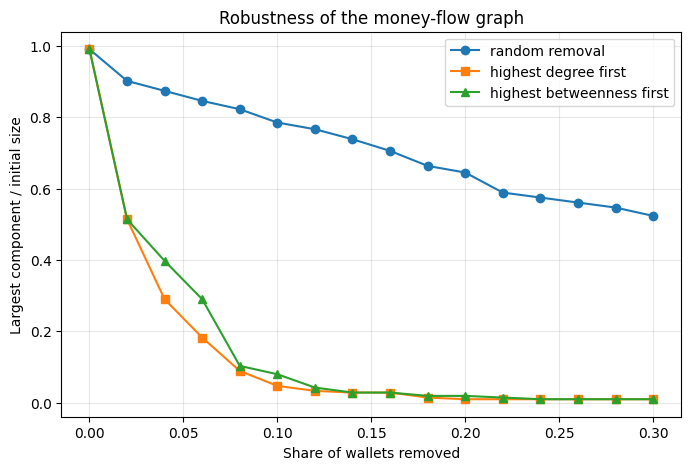

In [28]:
def robustness_curve(H, order, fractions):
    n = H.order()
    sizes = []
    for f in fractions:
        H2 = H.copy()
        H2.remove_nodes_from(order[: int(f * n)])
        sizes.append(len(max(nx.connected_components(H2), key=len)) / n if H2.order() else 0)
    return sizes

fractions = np.linspace(0, 0.3, 16)
rng = random.Random(SEED)
random_order = list(G_u.nodes); rng.shuffle(random_order)
degree_order = sorted(G_u.nodes, key=lambda n: G_u.degree(n), reverse=True)
betw_order = sorted(G_u.nodes, key=lambda n: measures["betweenness"].get(n, 0), reverse=True)

plt.figure(figsize=(8, 5))
plt.plot(fractions, robustness_curve(G_u, random_order, fractions), "o-", label="random removal")
plt.plot(fractions, robustness_curve(G_u, degree_order, fractions), "s-", label="highest degree first")
plt.plot(fractions, robustness_curve(G_u, betw_order, fractions), "^-", label="highest betweenness first")
plt.xlabel("Share of wallets removed")
plt.ylabel("Largest component / initial size")
plt.title("Robustness of the money-flow graph")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interpretation.** Random removals barely affect the network, while targeted removals make it collapse quickly: the graph is held together by a few hub wallets. This is typical of transaction networks, and it means that investigating a handful of central wallets is enough to understand how most money moves.

### 3.9 Laplacian Spectrum & Algebraic Connectivity

To quantify how easily this money-flow graph can be cut into separate groups, we analyze its **Normalized Laplacian Spectrum**.

For an undirected graph $G$, the normalized Laplacian matrix $\mathcal{L}$ is defined as:
$$ \mathcal{L} = I - D^{-1/2} A D^{-1/2} $$
where $I$ is the identity matrix, $A$ is the adjacency matrix, and $D$ is the diagonal degree matrix.

The eigenvalues of $\mathcal{L}$ (the spectrum) fall in the range $[0, 2]$.
* The **multiplicity of the $0$ eigenvalue** equals the number of connected components.
* The **second smallest eigenvalue ($\lambda_2$)**, also known as the **Fiedler value** or **Algebraic Connectivity**, measures how well-connected the graph is overall. A value close to $0$ indicates that the graph can be easily cut into independent communities (like isolated suspicious clusters), such as small groups of wallets around a common funder. Note that sparse transaction networks almost always have a low λ₂, so this value supports the community structure found above rather than proving coordination on its own.

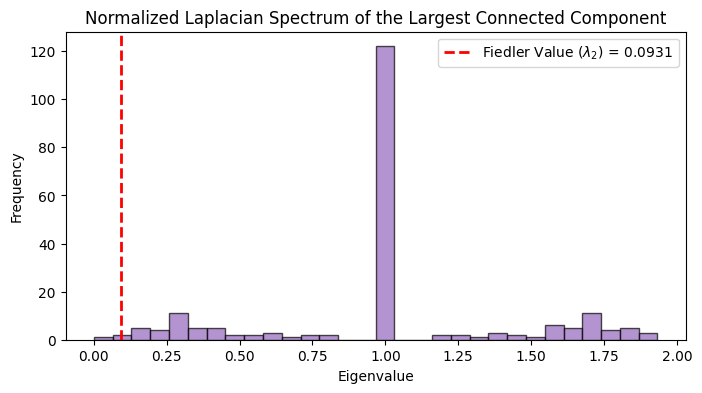

Algebraic connectivity (Fiedler value): 0.0931
Interpretation: a value close to 0 means the largest component can be split into groups with few edges between them, consistent with the high modularity found by Louvain. Sparse transaction graphs usually have a low value, so this supports the community structure but is not, by itself, evidence of coordinated wallets.


In [29]:
import scipy.linalg as la

# Use the largest (undirected) connected component so that the Fiedler value is meaningful
L = nx.normalized_laplacian_matrix(G_lcc).todense()
eigenvalues = la.eigvalsh(L)

# Extraction de la valeur de Fiedler (2ème plus petite valeur propre)
fiedler_value = eigenvalues[1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(eigenvalues, bins=30, color="tab:purple", alpha=0.7, edgecolor="black")
ax.axvline(fiedler_value, color='red', linestyle='dashed', linewidth=2, label=f'Fiedler Value ($\\lambda_2$) = {fiedler_value:.4f}')

ax.set_title("Normalized Laplacian Spectrum of the Largest Connected Component")
ax.set_xlabel("Eigenvalue")
ax.set_ylabel("Frequency")
ax.legend()
plt.show()

print(f"Algebraic connectivity (Fiedler value): {fiedler_value:.4f}")
print("Interpretation: a value close to 0 means the largest component can be split into groups "
      "with few edges between them, consistent with the high modularity found by Louvain. "
      "Sparse transaction graphs usually have a low value, so this supports the community "
      "structure but is not, by itself, evidence of coordinated wallets.")

---
## 4. Suspicious patterns

We now combine the betting data and the money flows. Each pattern below is a signal, not a proof; the score in 4.5 combines them.

### 4.1 Fresh wallets

How long before its first Iran bet was each winner first funded? A wallet funded a few hours or days before a big, well-timed bet matches the pattern described in public investigations.

60 of 150 winners were first funded less than 7 days before their first Iran bet


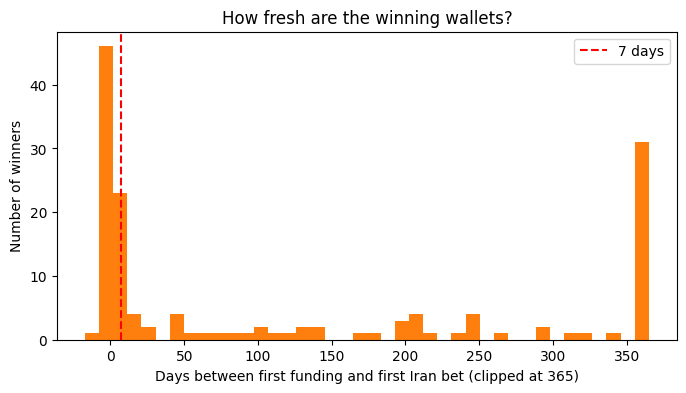

In [30]:
winners["first_funding"] = winners["wallet"].map(FIRST_FUNDING)
winners["days_funding_to_bet"] = (winners["first_bet"] - winners["first_funding"]).dt.total_seconds() / 86400
winners["fresh_wallet"] = winners["days_funding_to_bet"].between(-0.01, FRESH_WALLET_DAYS)

print(f"{winners['fresh_wallet'].sum()} of {len(winners)} winners were first funded less than "
      f"{FRESH_WALLET_DAYS} days before their first Iran bet")

plt.figure(figsize=(8, 4))
plt.hist(winners["days_funding_to_bet"].dropna().clip(upper=365), bins=40, color="tab:orange")
plt.axvline(FRESH_WALLET_DAYS, color="red", linestyle="--", label=f"{FRESH_WALLET_DAYS} days")
plt.xlabel("Days between first funding and first Iran bet (clipped at 365)")
plt.ylabel("Number of winners")
plt.title("How fresh are the winning wallets?")
plt.legend()
plt.show()

### 4.2 Long-shot wins and timing

Winning repeatedly on outcomes priced below 35% is statistically unlikely. We also look at how many hours before resolution the winning bets were placed.

In [31]:
wins = wallet_market[(wallet_market["wallet"].isin(winner_set)) & (wallet_market["profit"] > 0)]
timing = wins.groupby("wallet")["min_hours_before"].median().rename("median_hours_before_resolution")
winners = winners.merge(timing, on="wallet", how="left")

cols = ["wallet", "profit", "n_markets", "win_rate", "longshot_wins", "median_hours_before_resolution", "best_market"]
print("Winners with at least one long-shot win:")
winners[winners["longshot_wins"] > 0][cols].head(20).style.format(
    {"profit": "{:,.0f}", "win_rate": "{:.0%}", "median_hours_before_resolution": "{:.1f}"})

Winners with at least one long-shot win:


,wallet,profit,n_markets,win_rate,longshot_wins,median_hours_before_resolution,best_market
0,0x0a854897a06d4999e5b2dde5693609f1428ffe9d,"781,394",5,60%,26,57.7,Khamenei out as Supreme Leader of Iran by March 31?
1,0xbad457dc633bbb7b6cbe09dd5867a5e8e597acd7,"758,790",2,50%,9,74.0,Khamenei out as Supreme Leader of Iran by March 31?
2,0x37d10ffb61998561c5f9fb941c42c952d8fb4e28,"500,625",3,100%,12,77.6,"US strikes Iran by February 28, 2026?"
3,0x5ed3561e39d6c9a9622c6f84a782537df7f9b19e,"490,859",3,67%,7,145.6,"US strikes Iran by February 28, 2026?"
4,0x1caa6a7ad0c6916aef7b67946de2e57ad24846a0,"489,228",2,50%,6,5.8,"US strikes Iran by February 28, 2026?"
5,0xc851cd9bee7d262afd78674f861f9f576a12cd2a,"451,042",5,80%,5,203.0,"US strikes Iran by February 28, 2026?"
6,0xbaa2bcb5439e985ce4ccf815b4700027d1b92c73,"446,877",5,100%,17,152.8,Khamenei out as Supreme Leader of Iran by February 28?
7,0x7b02b2bac2a30ed5e40b7094e734f4c3dc2a4991,"416,998",3,100%,22,71.4,Khamenei out as Supreme Leader of Iran by February 28?
8,0x4dfd481c16d9995b809780fd8a9808e8689f6e4a,"363,300",3,100%,7,370.6,"US strikes Iran by February 28, 2026?"
9,0xde7be6d489bce070a959e0cb813128ae659b5f4b,"344,719",4,50%,12,40.0,Khamenei out as Supreme Leader of Iran by February 28?


### 4.3 Links between winning wallets

Two winners are **linked** if:
- one sent money directly to the other, or
- they share a **common funder** within `FUNDING_HOPS` transfers upstream (funder → … → winner).

We build a new graph whose nodes are the winners and whose edges are these links. Its connected components are the **clusters of linked winners**.

In [32]:
def upstream_funders(G, node, hops):
    # all wallets that sent money to `node`, directly or within `hops` steps
    seen, frontier = set(), {node}
    for _ in range(hops):
        nxt = set()
        for n in frontier:
            nxt |= set(G.predecessors(n)) if n in G else set()
        nxt -= seen | {node}
        seen |= nxt
        frontier = nxt
    return seen

winners_in_G = [w for w in winner_set if w in G]
funders_of = {w: upstream_funders(G, w, FUNDING_HOPS) for w in winners_in_G}

W = nx.Graph()
W.add_nodes_from(winners_in_G)
for i, a in enumerate(winners_in_G):
    for b in winners_in_G[i + 1:]:
        direct = G.has_edge(a, b) or G.has_edge(b, a)
        common = (funders_of[a] & funders_of[b]) - winner_set
        if direct or common:
            W.add_edge(a, b, direct=direct, common_funders=sorted(common))

clusters = sorted([c for c in nx.connected_components(W) if len(c) >= 2], key=len, reverse=True)
profit_of = winners.set_index("wallet")["profit"]

cluster_rows = []
for i, c in enumerate(clusters):
    funders = Counter(f for a, b, d in W.subgraph(c).edges(data=True) for f in d["common_funders"])
    cluster_rows.append({
        "cluster": i, "n_winners": len(c),
        "total_profit": sum(profit_of[w] for w in c),
        "direct_links": sum(1 for _, _, d in W.subgraph(c).edges(data=True) if d["direct"]),
        "main_common_funder": short(funders.most_common(1)[0][0]) if funders else "-",
        "markets": "; ".join(sorted(set(winners.set_index("wallet").loc[list(c), "best_market"])))[:120],
    })
for i, c in enumerate(clusters):
    for w in c:
        winners.loc[winners["wallet"] == w, "cluster"] = i
cluster_df = pd.DataFrame(cluster_rows)

print(f"{len(clusters)} clusters of linked winners, covering "
      f"{sum(len(c) for c in clusters)} of {len(winners_in_G)} winners in the graph")
cluster_df.style.format({"total_profit": "{:,.0f}"}) if len(cluster_df) else cluster_df

2 clusters of linked winners, covering 24 of 47 winners in the graph


,cluster,n_winners,total_profit,direct_links,main_common_funder,markets
0,0,20,"2,636,337",6,0xd152…2150,Khamenei out as Supreme Leader of Iran by February 28?; Khamenei out as Supreme Leader of Iran by March 31?; US strikes
1,1,4,"2,026,374",0,0xf70d…dbef,Khamenei out as Supreme Leader of Iran by February 28?; Khamenei out as Supreme Leader of Iran by March 31?


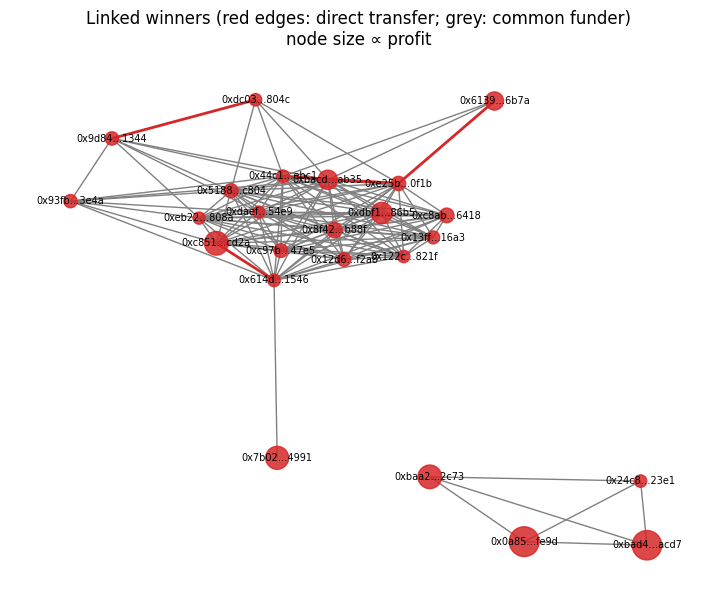

In [33]:
if W.size() > 0:
    Wc = W.subgraph([n for n in W if W.degree(n) > 0])
    plt.figure(figsize=(9, 7))
    pos = nx.spring_layout(Wc, seed=SEED, k=0.6)
    nx.draw_networkx_edges(Wc, pos, edge_color=["tab:red" if d["direct"] else "gray" for _, _, d in Wc.edges(data=True)],
                           width=[2 if d["direct"] else 1 for _, _, d in Wc.edges(data=True)])
    nx.draw_networkx_nodes(Wc, pos, node_color="tab:red", alpha=0.85,
                           node_size=[60 + 400 * profit_of[n] / profit_of.max() for n in Wc])
    nx.draw_networkx_labels(Wc, pos, {n: short(n) for n in Wc}, font_size=7)
    plt.title("Linked winners (red edges: direct transfer; grey: common funder)\nnode size ∝ profit")
    plt.axis("off")
    plt.show()
else:
    print("No links between winners were found.")

### 4.4 Redistribution of gains

For each winner and each market it won, we look at its **outgoing transfers in the `REDISTRIBUTION_WINDOW_DAYS` days after resolution** and flag the recipient when it is:
- another **winner**,
- a wallet **funded by the same upstream funder** as the winner,
- a wallet the **winner itself funded before** the bet,
- a wallet that **receives gains from several winners** in the window (a likely "collector").

These are the "gains sent back into the same group" flows described in the project question.

In [34]:
# resolution times of every market each winner won
resolutions_by_wallet = (wallet_market[(wallet_market["wallet"].isin(winner_set)) & (wallet_market["profit"] > 0)]
                         .groupby("wallet")["resolution_time"].apply(lambda s: sorted(s.dropna())))
window = pd.Timedelta(days=REDISTRIBUTION_WINDOW_DAYS)

# first pass: every post-resolution transfer of every winner, to find collectors
candidates = []
for w in winners_in_G:
    res_times = resolutions_by_wallet.get(w, [])
    if not res_times:
        continue
    for r in transfers_all[transfers_all["from"] == w].itertuples(index=False):
        previous = [t for t in res_times if t < r.timestamp]
        if previous and r.timestamp - previous[-1] <= window and r.to not in hubs:
            candidates.append((w, r.to))
senders_per_recipient = defaultdict(set)
for w, rec in candidates:
    senders_per_recipient[rec].add(w)

flows = []
for w in winners_in_G:
    res_times = resolutions_by_wallet.get(w, [])
    if not res_times:
        continue
    out = transfers_all[transfers_all["from"] == w]
    for r in out.itertuples(index=False):
        # most recent resolution before this transfer; keep the transfer if it falls inside the window
        previous = [t for t in res_times if t < r.timestamp]
        if not previous or r.timestamp - previous[-1] > window:
            continue
        res_t = previous[-1]
        rec = r.to
        if rec in hubs:
            continue
        reasons = []
        if rec in winner_set:
            reasons.append("recipient is a winner")
        shared = (funders_of[w] & upstream_funders(G, rec, FUNDING_HOPS)) - {w, rec} if rec in G else set()
        if shared:
            reasons.append("shares a funder with the winner")
        before = transfers_all[(transfers_all["from"] == w) & (transfers_all["to"] == rec)
                               & (transfers_all["timestamp"] < res_t)]
        if len(before):
            reasons.append("funded by the winner before")
        if len(senders_per_recipient.get(rec, ())) >= 2:
            reasons.append(f"receives gains from {len(senders_per_recipient[rec])} winners")
        if reasons:
            flows.append({"winner": w, "recipient": rec, "amount": r.amount,
                          "hours_after_resolution": (r.timestamp - res_t).total_seconds() / 3600,
                          "reasons": ", ".join(reasons),
                          "common_funders": ", ".join(short(f) for f in sorted(shared))})

redistribution = pd.DataFrame(flows)
if len(redistribution):
    redistribution = redistribution.sort_values("amount", ascending=False)
    print(f"{len(redistribution)} suspicious post-resolution transfers from {redistribution['winner'].nunique()} winners, "
          f"total {redistribution['amount'].sum():,.0f} USD")
    show = redistribution.assign(winner=redistribution["winner"].map(short),
                                 recipient=redistribution["recipient"].map(short))
    display(show.head(20).style.format({"amount": "{:,.0f}", "hours_after_resolution": "{:.1f}"}))
else:
    print("No redistribution towards related wallets was found.")

No redistribution towards related wallets was found.


### 4.5 Suspicion score

We combine the signals into a simple, transparent score (one point per signal, maximum 6):

| Signal | Point |
|---|---|
| Fresh wallet (funded < `FRESH_WALLET_DAYS` days before the first bet) | 1 |
| At least one long-shot win | 1 |
| Two or more long-shot wins | +1 |
| Win rate ≥ 80% on at least 2 markets | 1 |
| Linked to another winner (direct transfer or common funder) | 1 |
| Redistributed gains to a related wallet | 1 |

The score is a ranking tool to decide which wallets to look at first, not a verdict.

In [35]:
linked = {n for n in W if W.degree(n) > 0}
redistributors = set(redistribution["winner"]) if len(redistribution) else set()

winners["linked_to_winner"] = winners["wallet"].isin(linked)
winners["redistributed"] = winners["wallet"].isin(redistributors)
winners["score"] = (winners["fresh_wallet"].astype(int)
                    + (winners["longshot_wins"] >= 1).astype(int)
                    + (winners["longshot_wins"] >= 2).astype(int)
                    + ((winners["win_rate"] >= 0.8) & (winners["n_markets"] >= 2)).astype(int)
                    + winners["linked_to_winner"].astype(int)
                    + winners["redistributed"].astype(int))

ranking = winners.sort_values(["score", "profit"], ascending=False)
cols = ["wallet", "score", "profit", "win_rate", "n_markets", "longshot_wins", "fresh_wallet",
        "linked_to_winner", "redistributed", "best_market"]
ranking[cols].head(20).style.format({"profit": "{:,.0f}", "win_rate": "{:.0%}"}).background_gradient(
    subset=["score"], cmap="Reds")

,wallet,score,profit,win_rate,n_markets,longshot_wins,fresh_wallet,linked_to_winner,redistributed,best_market
7,0x7b02b2bac2a30ed5e40b7094e734f4c3dc2a4991,5,"416,998",100%,3,22,True,True,False,Khamenei out as Supreme Leader of Iran by February 28?
1,0xbad457dc633bbb7b6cbe09dd5867a5e8e597acd7,4,"758,790",50%,2,9,True,True,False,Khamenei out as Supreme Leader of Iran by March 31?
5,0xc851cd9bee7d262afd78674f861f9f576a12cd2a,4,"451,042",80%,5,5,False,True,False,"US strikes Iran by February 28, 2026?"
6,0xbaa2bcb5439e985ce4ccf815b4700027d1b92c73,4,"446,877",100%,5,17,False,True,False,Khamenei out as Supreme Leader of Iran by February 28?
10,0xdbf16bcffa41bd95faec2640daa2c95ab2bd86b5,4,"335,798",100%,1,9,True,True,False,"US strikes Iran by February 28, 2026?"
11,0x09d3273fa76282ce09f4f35a87d6f087c05f4e84,4,"330,066",100%,2,5,True,False,False,"US strikes Iran by February 28, 2026?"
12,0x514550b8f94f24e3bd5fca1c8af19e985fb71f46,4,"329,968",100%,2,9,True,False,False,"US strikes Iran by February 28, 2026?"
13,0x607fec58640fcea5cb837adb09d658747720592c,4,"304,076",100%,2,7,True,False,False,"US strikes Iran by February 28, 2026?"
15,0xbacd00c9080a82ded56f504ee8810af732b0ab35,4,"262,013",100%,5,18,False,True,False,"US strikes Iran by February 28, 2026?"
20,0x0c8bc7db08d5fa2ceedb919c6a2d6ab60b7823de,4,"207,529",100%,3,10,True,False,False,"US strikes Iran by February 28, 2026?"


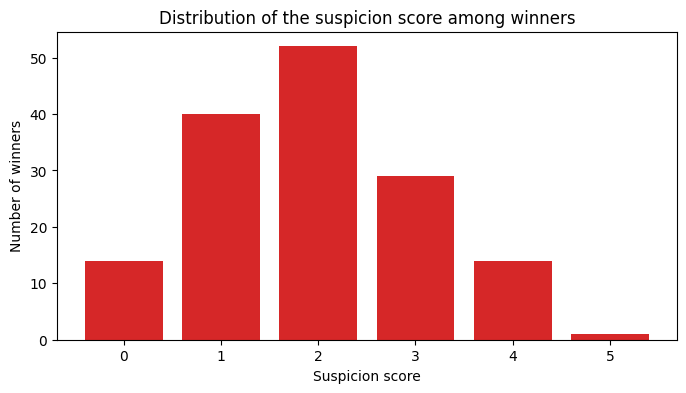

       count        sum    median
score                            
0         14   913792.0   42147.0
1         40  2220327.0   39861.0
2         52  3882053.0   54144.0
3         29  5004589.0   87355.0
4         14  3872114.0  283045.0
5          1   416998.0  416998.0


In [36]:
plt.figure(figsize=(8, 4))
score_counts = winners["score"].value_counts().sort_index()
plt.bar(score_counts.index, score_counts.values, color="tab:red")
plt.xlabel("Suspicion score")
plt.ylabel("Number of winners")
plt.title("Distribution of the suspicion score among winners")
plt.show()

print(winners.groupby("score")["profit"].agg(["count", "sum", "median"]).round(0))

---
## 5. Visualisation, export and conclusion

### 5.1 Zoom on the most profitable cluster

We draw the money flows around the cluster of linked winners with the highest total profit: the winners themselves, their funders and the recipients of their gains.

- 🔴 winners (size ∝ profit)
- 🟠 funders of the winners
- 🔵 recipients of post-resolution transfers
- edge width ∝ amount transferred

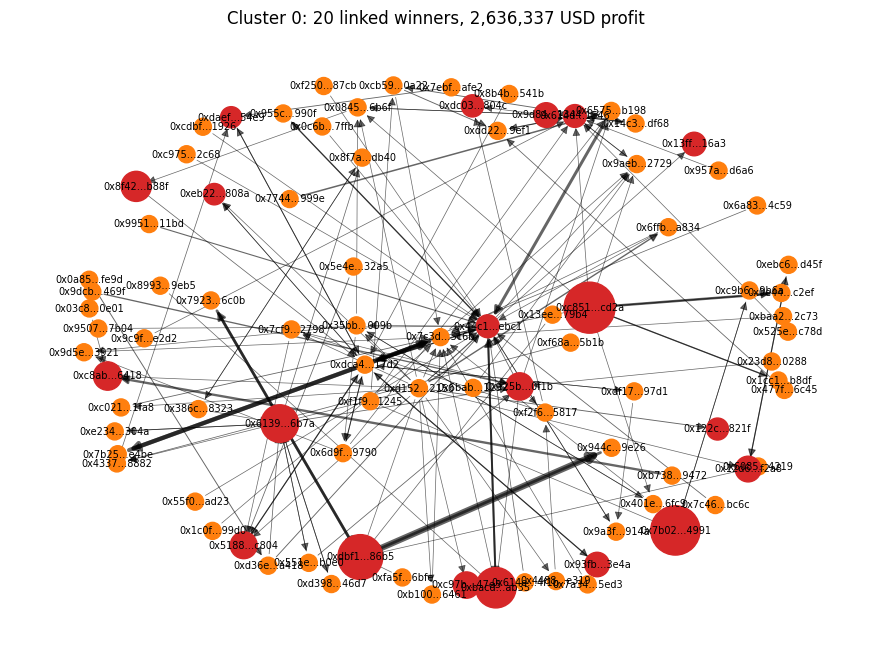

In [37]:
if len(cluster_df):
    best_cluster = cluster_df.sort_values("total_profit", ascending=False).iloc[0]["cluster"]
    c_winners = set(winners.loc[winners["cluster"] == best_cluster, "wallet"])
    c_funders = set().union(*(funders_of[w] for w in c_winners)) - c_winners
    c_recipients = (set(redistribution[redistribution["winner"].isin(c_winners)]["recipient"])
                    if len(redistribution) else set())
    nodes = (c_winners | c_funders | c_recipients) & set(G.nodes)
    S = G.subgraph(nodes)

    def colour(n):
        if n in c_winners: return "tab:red"
        if n in c_recipients: return "tab:blue"
        return "tab:orange"

    max_profit = max(G.nodes[n]["profit"] for n in c_winners)
    max_amount = max(d["amount"] for _, _, d in S.edges(data=True))
    plt.figure(figsize=(11, 8))
    pos = nx.spring_layout(S, seed=SEED, k=0.9)
    nx.draw_networkx_edges(S, pos, arrows=True, arrowsize=12, alpha=0.6,
                           width=[0.5 + 4 * d["amount"] / max_amount for _, _, d in S.edges(data=True)])
    nx.draw_networkx_nodes(S, pos, node_color=[colour(n) for n in S],
                           node_size=[150 + 1200 * G.nodes[n]["profit"] / max_profit if n in c_winners else 150 for n in S])
    nx.draw_networkx_labels(S, pos, {n: short(n) for n in S}, font_size=7)
    plt.title(f"Cluster {int(best_cluster)}: {len(c_winners)} linked winners, "
              f"{sum(G.nodes[n]['profit'] for n in c_winners):,.0f} USD profit")
    plt.axis("off")
    plt.show()
else:
    print("No cluster of linked winners to display.")

### 5.2 Summary table for the presentation

In [38]:
summary = {
    "Iran-related resolved markets": len(markets),
    "Wallets that traded": trades["wallet"].nunique(),
    f"Winners (profit ≥ {MIN_PROFIT:,} USD)": len(winners),
    "Profit of these winners (USD)": round(winners["profit"].sum()),
    "Graph nodes / edges (after cleaning)": f"{G.order()} / {G.size()}",
    "Density": round(nx.density(G), 6),
    "Weakly connected components": nx.number_weakly_connected_components(G),
    "Largest component share": f"{len(wccs[0]) / G.order():.1%}",
    "Diameter / radius (largest component)": f"{dist['diameter']} / {dist['radius']}",
    "Average shortest path (largest component)": round(dist["avg_shortest_path"], 2),
    "Average clustering": round(nx.average_clustering(G_u), 4),
    "Louvain communities / modularity": f"{len(communities)} / {modularity:.3f}",
    "Clusters of linked winners": len(clusters),
    "Winners in a cluster": int(winners["linked_to_winner"].sum()),
    "Winners with score ≥ 4": int((winners["score"] >= 4).sum()),
    "Profit of winners with score ≥ 4 (USD)": round(winners.loc[winners["score"] >= 4, "profit"].sum()),
}
pd.Series(summary, name="value").to_frame()

,value
Iran-related resolved markets,5
Wallets that traded,82596
"Winners (profit ≥ 1,000 USD)",150
Profit of these winners (USD),16309873
Graph nodes / edges (after cleaning),214 / 326
Density,0.007152
Weakly connected components,2
Largest component share,99.1%
Diameter / radius (largest component),7 / 4
Average shortest path (largest component),3.26


### 5.3 Export

In [39]:
os.makedirs("/content/drive/MyDrive/graph_results", exist_ok=True)
ranking.to_csv("/content/drive/MyDrive/graph_results/winners_ranked.csv", index=False)
cluster_df.to_csv("/content/drive/MyDrive/graph_results/winner_clusters.csv", index=False)
redistribution.to_csv("/content/drive/MyDrive/graph_results/redistribution_flows.csv", index=False)
community_df.to_csv("/content/drive/MyDrive/graph_results/communities.csv", index=False)
nx.write_graphml(nx.relabel_nodes(
    nx.DiGraph([(u, v, {"amount": d["amount"], "count": d["count"]}) for u, v, d in G.edges(data=True)]), str),
    "/content/drive/MyDrive/graph_results/money_flow_graph.graphml")
print("Saved to /content/drive/MyDrive/graph_results/:", os.listdir("/content/drive/MyDrive/graph_results/"))

Saved to /content/drive/MyDrive/graph_results/: ['communities.csv', 'redistribution_flows.csv', 'money_flow_graph.graphml', 'winner_clusters.csv', 'winners_ranked.csv']


### 5.4 Conclusion and limitations

**What the graph shows.** After removing exchanges and Polymarket contracts, the money-flow graph is sparse, made of many small components and held together by a few hubs. Most winners are isolated, which is what we expect from independent bettors. The interesting findings are the exceptions: groups of winners connected by direct transfers or common funders, often fresh wallets with repeated long-shot wins placed shortly before resolution, and that move their gains to related wallets afterwards.

**Limitations.**
- *Signals, not proof*: shared funders can be coincidental (a friend, an OTC desk, a small exchange below the hub threshold), and some traders legitimately use several wallets.
- *Hub threshold*: too low and we cut real links, too high and exchanges create false links. Test several values and check that the clusters are stable.
- *Coverage*: the public trade feed can be capped on large markets, and we only follow stablecoin transfers, so swaps through other tokens, bridges or mixers break the trail.
- *Timing*: we do not know when information became public in each case; comparing bet times with the first news reports would strengthen the analysis.

**Possible extensions.** Compare the clusters found with publicly reported cases; add other tokens and cross-chain bridges; use the time dimension (a temporal graph) to follow the sequence *funding → bet → resolution → redistribution*; or train a classifier on wallet features.